# RAG evaluation report: LlamaIndex + Ollama + ChromaDB on FiQA

This notebook documents the RAGAS evaluation runs made with `eval/run_eval.py`. It covers how the pipeline is set up, what each metric measures, which constants were changed between runs, and how each change moved the metrics.

All tables and charts are computed from the files in `eval/results/`. The runtime figures in §10 come from `eval/logs/`.

## Key findings

1. **Fixing the judge prompt changed answer relevancy more than any pipeline change did.** Re-scoring the *same* baseline answers with the calibrated noncommittal prompt raised answer relevancy from 0.256 to 0.432 (+0.175, 95% CI +0.12 to +0.24). The stock RAGAS prompt gave a score of 0 to 33 answers that were not refusals.
2. **The relaxed generation prompt raises faithfulness because it stops refusing, not because its answers are better grounded.** Mean faithfulness rose from 0.645 to 0.811. All of the gain comes from the 33 questions the strict prompt refused (0.06 → 0.68). On the 67 questions the strict prompt did not refuse, faithfulness *fell* from 0.932 to 0.878.
3. **The relaxed prompt did not measurably change answer relevancy** (+0.02, CI −0.05 to +0.09). 21 of its answers still contain the refusal sentence alongside partial content, and the judge scores all 21 as noncommittal (0).
4. **Raising `TOP_K` from 3 to 10 improves recall and relevancy, at a cost.** Context recall rose by 0.117 and answer relevancy by 0.090 (both CIs exclude 0). Faithfulness rose by 0.044 (CI includes 0) and context precision fell by 0.036. Mean latency per question went from 29 s to 55 s.
5. **Retrieval sets the ceiling.** The question's own reference document is in the top 3 chunks for 58 of 100 questions and in the top 10 for 69. For the remaining 31, context recall averages 0.36 even at `top_k = 10`.

**Best configuration measured: relaxed prompt, `top_k = 10`.** It has the highest faithfulness, answer relevancy and context recall, but roughly doubles latency and slightly lowers context precision.

## Contents

1. Experiment setup
2. Metrics
3. Runs and comparison design
4. Load the results
5. Scorecard
6. How each constant changed the metrics
7. Variable 1: answer-relevancy judge prompt
8. Variable 2: generation prompt (strict → relaxed)
9. Variable 3: `TOP_K` (3 → 10)
10. Runtime cost
11. Question-level view
12. Caveats
13. Conclusions and next experiments

## 1. Experiment setup

### Pipeline

```text
question ──► nomic-embed-text ──► ChromaDB similarity search (top_k chunks)
                                          │
                                          ▼
                  qwen2.5:7b  (system prompt + retrieved chunks + question) ──► answer
                                          │
           question, answer, retrieved chunks, reference answer
                                          ▼
                     RAGAS 0.4 with qwen2.5:7b as judge ──► 4 metric scores per question
```

### Data

* **Golden set:** 100 questions from the FiQA test split, shuffled with seed 42 (`eval/prepare_golden_dataset.py`). Each question has a human-written reference answer.
* **Index:** a 5,000-passage sample of the FiQA corpus (seed 42, `ingest_fiqa.py`). Each golden reference answer was then added as its own document named `fiqa_gold_XXXX` (`eval/add_references_to_index.py`). References already in the corpus sample were not added again.
  Without this step only about 11 of the 100 references could be retrieved, so the context metrics measured corpus coverage rather than retrieval quality. For any one question, the other 99 references stay in the index as distractors.

### Constants held fixed in every run (`config.py`)

| Constant | Value | Role |
|---|---|---|
| `CHUNK_SIZE` / `CHUNK_OVERLAP` | 512 / 50 tokens | `SentenceSplitter` chunking |
| `EMBED_MODEL` | `nomic-embed-text` | retrieval embeddings, and the embeddings used inside answer relevancy |
| `LLM_MODEL` | `qwen2.5:7b` | answer generation |
| `LLM_CONTEXT_WINDOW` | 4096 | `num_ctx` for generation |
| `JUDGE_MODEL` | `qwen2.5:7b` | RAGAS judge: temperature 0, `format="json"`, `num_ctx` 8192, `num_predict` 2048 |
| `JUDGE_TIMEOUT` | 600 s | one judge call at a time (`max_workers=1`) |

### Constants that were varied

| Constant | Values tested | Where it is set |
|---|---|---|
| `TOP_K` (chunks retrieved per question) | **3** (`config.TOP_K`), **10** | `run_eval.py --top-k` |
| Generation prompt | **strict**, **relaxed** | `run_eval.py --prompt`, `config.PROMPT_VARIANTS` |
| Answer-relevancy judge prompt | **stock** RAGAS prompt, **calibrated** prompt | `CalibratedResponseRelevancePrompt` in `run_eval.py` |

**Strict system prompt (baseline).** It answers only when the context states the answer:

> You are a precise question-answering assistant. Answer ONLY using the information provided in the context below. Do not use any prior knowledge, training data, or outside information. If the answer cannot be found in the provided context, respond with exactly: 'I don't know based on the provided documents.' Never guess, fabricate, or extrapolate beyond what the context explicitly states.

**Relaxed system prompt.** It answers from partial context:

> You are a helpful question-answering assistant. Base your answer on the information in the context below and give the most useful answer you can from it. If the context only partly answers the question, answer the parts it supports and say what is missing. Only respond with 'I don't know based on the provided documents.' if the context contains nothing relevant to the question. Do not state facts that the context does not support.

**Calibrated answer-relevancy judge prompt.** The stock RAGAS prompt flags an answer as *noncommittal* when it is "evasive, vague, or ambiguous", and a noncommittal answer scores 0. The 7B judge applied that flag to answers that contained any caveat. The calibrated prompt sets the flag only when the answer declines to answer, and adds three generic examples that are not taken from the golden set.

## 2. Metrics

All four are RAGAS 0.4 LLM-judged metrics, scored per question in [0, 1] and averaged over the 100 questions.

| Metric | Question it answers | What the judge sees | How the score is computed | Changed by |
|---|---|---|---|---|
| **Faithfulness** | Is every claim in the answer supported by the retrieved chunks? | answer, retrieved chunks | The judge splits the answer into statements and checks each against the chunks. Score = supported statements ÷ all statements. | generation prompt, retrieved chunks |
| **Answer relevancy** | Does the answer address the question? | answer (the question enters only via embeddings) | The judge writes questions that the answer would answer, plus a *noncommittal* flag. Score = mean cosine similarity between those questions and the real one, × (1 − noncommittal). | generation prompt, **judge prompt** |
| **Context precision** | Are the useful chunks ranked near the top? | question, reference, retrieved chunks | The judge marks each chunk useful or not for reaching the reference. Score = Σₖ precision@k · vₖ ÷ (number of useful chunks), a rank-weighted average precision. | retrieval only |
| **Context recall** | Do the chunks contain what the reference answer says? | question, reference, retrieved chunks | The judge splits the reference into sentences and checks whether each can be attributed to the chunks. Score = attributed ÷ all. | retrieval only |

Consequences for reading the results:

* **Context precision and context recall never see the generated answer.** Changing only the generation prompt cannot change them. The relaxed@3 run scored only faithfulness and answer relevancy, so it reuses the baseline's context scores. This is valid because both runs retrieved identical chunks for all 100 questions (checked in §4).
* **A refusal scores 0 on answer relevancy** (noncommittal = 1) and almost always 0 on faithfulness, because the judge cannot match "I don't know" to anything in the context.
* **Answer relevancy never reaches 1.0**, since it is a cosine similarity between embeddings.
* **Context precision rewards ranking, not volume.** Extra chunks that the judge marks useful but that sit low in the list *lower* the score. §9 shows this.

## 3. Runs and comparison design

| Run | File in `eval/results/` | `TOP_K` | Generation prompt | AR judge prompt | Metrics scored | Date |
|---|---|---|---|---|---|---|
| **A**: strict@3, stock judge | `results_normal.json` | 3 | strict | stock | all 4 | 2026-10-05 |
| **B**: strict@3 | `results_answer_relevancy.json` | 3 | strict | calibrated | answer relevancy only (re-scored run A's cached answers) | 2026-10-05 |
| **C**: relaxed@3 | `results_relaxed_faithfulness+answer_relevancy.json` | 3 | relaxed | calibrated | faithfulness, answer relevancy | 2026-10-13 |
| **D**: relaxed@10 | `results_topk10_relaxed.json` | 10 | relaxed | calibrated | all 4 | 2026-10-06 |

In the rest of the notebook a *configuration* means a generation setup, written as `prompt@top_k`:

* **strict@3** takes faithfulness and the context metrics from run A, and answer relevancy from run B (same answers, calibrated judge).
* **relaxed@3** is run C. Its context precision and context recall are inherited from strict@3, which has identical retrieval.
* **relaxed@10** is run D.
* **strict@3 · stock AR judge** is run A's answer-relevancy score. It is kept only to show the effect of the judge prompt.

**Which comparison isolates which constant**

| Constant changed | Comparison | Held equal |
|---|---|---|
| AR judge prompt | A → B (answer relevancy) | identical answers and chunks |
| Generation prompt | strict@3 → relaxed@3 | `top_k = 3`, identical chunks, calibrated judge |
| `TOP_K` | relaxed@3 → relaxed@10 | relaxed prompt, calibrated judge |

**Coverage of the prompt × `TOP_K` grid**

| | `top_k = 3` | `top_k = 10` |
|---|---|---|
| **strict** | ✅ runs A + B | ❌ not run (`logs/run_topk10.log` holds only import warnings; no results were written) |
| **relaxed** | ✅ run C | ✅ run D |

Because strict@10 is missing, the effect of `TOP_K` is known only under the relaxed prompt. Whether it would differ under the strict prompt (an interaction) cannot be tested.

## 4. Load the results

Re-running this notebook needs `pandas`, `numpy` and `matplotlib` in the kernel. All three are installed by `pip install -r requirements.txt`.

In [1]:
import json
import re
import textwrap
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import ScaledTranslation

%config InlineBackend.figure_format = "retina"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)

# Works whether the notebook is run from eval/ or from the repository root
RESULTS_DIR = next(p for p in [Path("results"), Path("eval/results")] if p.is_dir())
RESULTS_DIR.resolve()

PosixPath('/Users/daimabbaskazmi/Documents/AI Eng Project/llamaindex-rag-eval/eval/results')

In [2]:
# ── Chart style ──────────────────────────────────────────────────────────────
# Colors come from a palette checked for color-vision-deficiency separation between neighboring marks.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RUN_COLORS = {"strict@3": "#2a78d6", "relaxed@3": "#eb6834", "relaxed@10": "#1baf7a"}
STOCK_GRAY = "#a9a8a1"  # the superseded stock judge prompt
ANSWER_TYPE_COLORS = {"Answered": "#3a3936", "Hedged": "#7a7974", "Refused": "#b8b7b0"}  # ordinal: more ink = more answer
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#e4effc", "#b7d3f6", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
)
SEQ.set_bad("#e9e8e3")

_installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"] if f in _installed), "DejaVu Sans")
mpl.rcParams.update({
    "font.family": [FONT, "DejaVu Sans"], "font.size": 10,  # DejaVu fills in missing glyphs (→)
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 10,
    "legend.frameon": False, "legend.fontsize": 9,
})


def header(fig, title, subtitle=None):
    # Left-aligned figure title and a one-line subtitle; returns the top edge to pass to tight_layout(rect=...)
    shift = lambda pt: fig.transFigure + ScaledTranslation(0, -pt / 72, fig.dpi_scale_trans)
    fig.text(0.012, 1, title, ha="left", va="top", fontsize=12.5, fontweight="bold", color=INK, transform=shift(10))
    if subtitle:
        fig.text(0.012, 1, subtitle, ha="left", va="top", fontsize=9.5, color=INK_2, transform=shift(29))
    return 1 - (58 if subtitle else 38) / 72 / fig.get_figheight()


def label_bars(ax, bars, fmt="{:.2f}", **kw):
    ax.bar_label(bars, labels=[fmt.format(b.get_width() if kw.get("horizontal") else b.get_height()) for b in bars],
                 padding=3, fontsize=8.5, color=INK_2)


def ink_for(rgba):
    # White text on dark fills, ink on light ones
    r, g, b = rgba[:3]
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK

In [3]:
FILES = {
    "A": "results_normal.json",
    "B": "results_answer_relevancy.json",
    "C": "results_relaxed_faithfulness+answer_relevancy.json",
    "D": "results_topk10_relaxed.json",
}
raw = {run: json.loads((RESULTS_DIR / f).read_text()) for run, f in FILES.items()}
A, B, C, D = (pd.DataFrame(raw[run]["samples"]).set_index("id") for run in "ABCD")

pd.DataFrame({
    run: {"file": FILES[run], **{m: raw[run]["aggregate"].get(m) for m in
          ["faithfulness", "answer_relevancy", "context_precision", "context_recall"]},
          "samples scored": raw[run]["scored"]}
    for run in "ABCD"
}).T

,file,faithfulness,answer_relevancy,context_precision,context_recall,samples scored
A,results_normal.json,0.644,0.256,0.483,0.657,"{'n_samples': 100, 'faithfulness': 100, 'answer_relevancy': 100, 'context_pr..."
B,results_answer_relevancy.json,None,0.432,None,None,"{'n_samples': 100, 'answer_relevancy': 100}"
C,results_relaxed_faithfulness+answer_relevancy.json,0.811,0.454,None,None,"{'n_samples': 100, 'faithfulness': 100, 'answer_relevancy': 100}"
D,results_topk10_relaxed.json,0.855,0.544,0.448,0.771,"{'n_samples': 100, 'faithfulness': 100, 'answer_relevancy': 100, 'context_pr..."


**Sanity checks.** These confirm the assumptions behind the comparisons: the re-score used identical answers, and the top-3 runs and the top-10 run retrieved consistent chunks.

In [4]:
checks = {
    "Same 100 question ids, same order, in every run": all(df.index.equals(A.index) for df in (B, C, D)),
    "Run B re-scored run A's answers (identical responses)": (A.response == B.response).all(),
    "Run C retrieved exactly the same chunks as run A": all(a == c for a, c in zip(A.retrieved_contexts, C.retrieved_contexts)),
    "Run D's first 3 chunks are run A's 3 chunks, in order": all(d[:3] == a for a, d in zip(A.retrieved_contexts, D.retrieved_contexts)),
    "Chunks per question: 3 in A/C, 10 in D": A.retrieved_contexts.str.len().eq(3).all() and D.retrieved_contexts.str.len().eq(10).all(),
}
pd.Series(checks, name="holds").to_frame()

,holds
"Same 100 question ids, same order, in every run",True
Run B re-scored run A's answers (identical responses),True
Run C retrieved exactly the same chunks as run A,True
"Run D's first 3 chunks are run A's 3 chunks, in order",True
"Chunks per question: 3 in A/C, 10 in D",True


Retrieval is deterministic and the top 3 are a prefix of the top 10. So one top-10 list per question tells us exactly what any `top_k ≤ 10` would retrieve. §9 uses this to draw the reference hit rate at every k.

Next, build one per-question table. Each column is one metric under one configuration, and each question gets a few labels:

* **`gold_rank`**: the position of the question's own reference document among the 10 retrieved chunks.
* **answer type**: *Refused* is exactly the refusal sentence. *Hedged* contains the refusal sentence along with other content. *Answered* is everything else.

In [5]:
METRICS = ["faithfulness", "answer_relevancy", "context_precision", "context_recall"]
SHORT = {"faithfulness": "Faithfulness", "answer_relevancy": "Answer relevancy",
         "context_precision": "Context precision", "context_recall": "Context recall"}
PATH = ["strict@3", "relaxed@3", "relaxed@10"]        # the order the experiments moved in
STOCK = "strict@3 · stock AR judge"
REFUSAL = "I don't know based on the provided documents."

per_q = pd.DataFrame({
    (STOCK, "answer_relevancy"): A.answer_relevancy,
    ("strict@3", "faithfulness"): A.faithfulness,
    ("strict@3", "answer_relevancy"): B.answer_relevancy,
    ("strict@3", "context_precision"): A.context_precision,
    ("strict@3", "context_recall"): A.context_recall,
    ("relaxed@3", "faithfulness"): C.faithfulness,
    ("relaxed@3", "answer_relevancy"): C.answer_relevancy,
    # Inherited: identical chunks (checked above), and these metrics never see the answer
    ("relaxed@3", "context_precision"): A.context_precision,
    ("relaxed@3", "context_recall"): A.context_recall,
    **{("relaxed@10", m): D[m] for m in METRICS},
})
INHERITED = {("relaxed@3", "context_precision"), ("relaxed@3", "context_recall")}


def norm(s):
    return re.sub(r"\s+", " ", s).strip()


def gold_rank(row):
    # 1-based rank of the question's own reference among D's 10 chunks; NaN if absent.
    # Matches the injected fiqa_gold_XXXX document by name, or a corpus chunk whose text is part of the reference
    # (references already present in the corpus sample were not injected again).
    gold_id = row.name.replace("fiqa_", "fiqa_gold_")
    ref = norm(row.reference)
    for rank, (src, ctx) in enumerate(zip(row.source_nodes, row.retrieved_contexts), 1):
        c = norm(ctx)
        if src == gold_id or (len(c) > 30 and (c[:200] in ref or ref[:200] in c)):
            return rank
    return np.nan


def answer_type(text):
    if text.strip() == REFUSAL:
        return "Refused"
    return "Hedged" if "don't know based on the provided documents" in text else "Answered"


q = pd.DataFrame(index=A.index)
q["question"] = A.user_input
q["gold_rank"] = D.apply(gold_rank, axis=1)
q["gold_group"] = pd.cut(q.gold_rank.fillna(99), [0, 3, 10, 100],
                         labels=["Reference in top 3", "Reference at rank 4–10", "Reference not in top 10"])
for cfg, df in [("strict@3", A), ("relaxed@3", C), ("relaxed@10", D)]:
    q[f"type {cfg}"] = df.response.map(answer_type)
    q[f"words {cfg}"] = df.response.str.split().str.len()
    q[f"latency {cfg}"] = df.latency_s
q["strict refused"] = q["type strict@3"].eq("Refused")
q.head()

,question,gold_rank,gold_group,type strict@3,words strict@3,latency strict@3,type relaxed@3,words relaxed@3,latency relaxed@3,type relaxed@10,words relaxed@10,latency relaxed@10,strict refused
id,,,,,,,,,,,,,
fiqa_0000,When to sell a stock?,NaN,Reference not in top 10,Refused,8,24.85,Answered,121,33.36,Answered,270,62.50,True
fiqa_0001,Should you keep your stocks if you are too late to sell?,NaN,Reference not in top 10,Answered,129,27.01,Answered,277,40.51,Answered,282,68.59,False
fiqa_0002,Purchasing ETFs when (pretty much) everything else is maxed out,1.0,Reference in top 3,Answered,86,20.26,Answered,226,36.01,Answered,304,61.32,False
fiqa_0003,Why naked call writing is risky compare to Covered call?,3.0,Reference in top 3,Answered,109,22.19,Answered,144,25.42,Answered,169,46.93,False
fiqa_0004,Can increasing my tax withholding from my full-time job cover FICA taxes for...,2.0,Reference in top 3,Refused,8,14.28,Answered,155,30.72,Answered,239,61.35,True


In [6]:
RNG = np.random.default_rng(42)


def bootstrap_ci(x, n_boot=10_000, alpha=0.05):
    # Mean and percentile bootstrap CI over questions; NaN (failed judge calls) are dropped
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    means = x[RNG.integers(0, len(x), (n_boot, len(x)))].mean(axis=1)
    lo, hi = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return x.mean(), lo, hi

## 5. Scorecard

Mean score per configuration, with a 95% bootstrap confidence interval over the 100 questions.

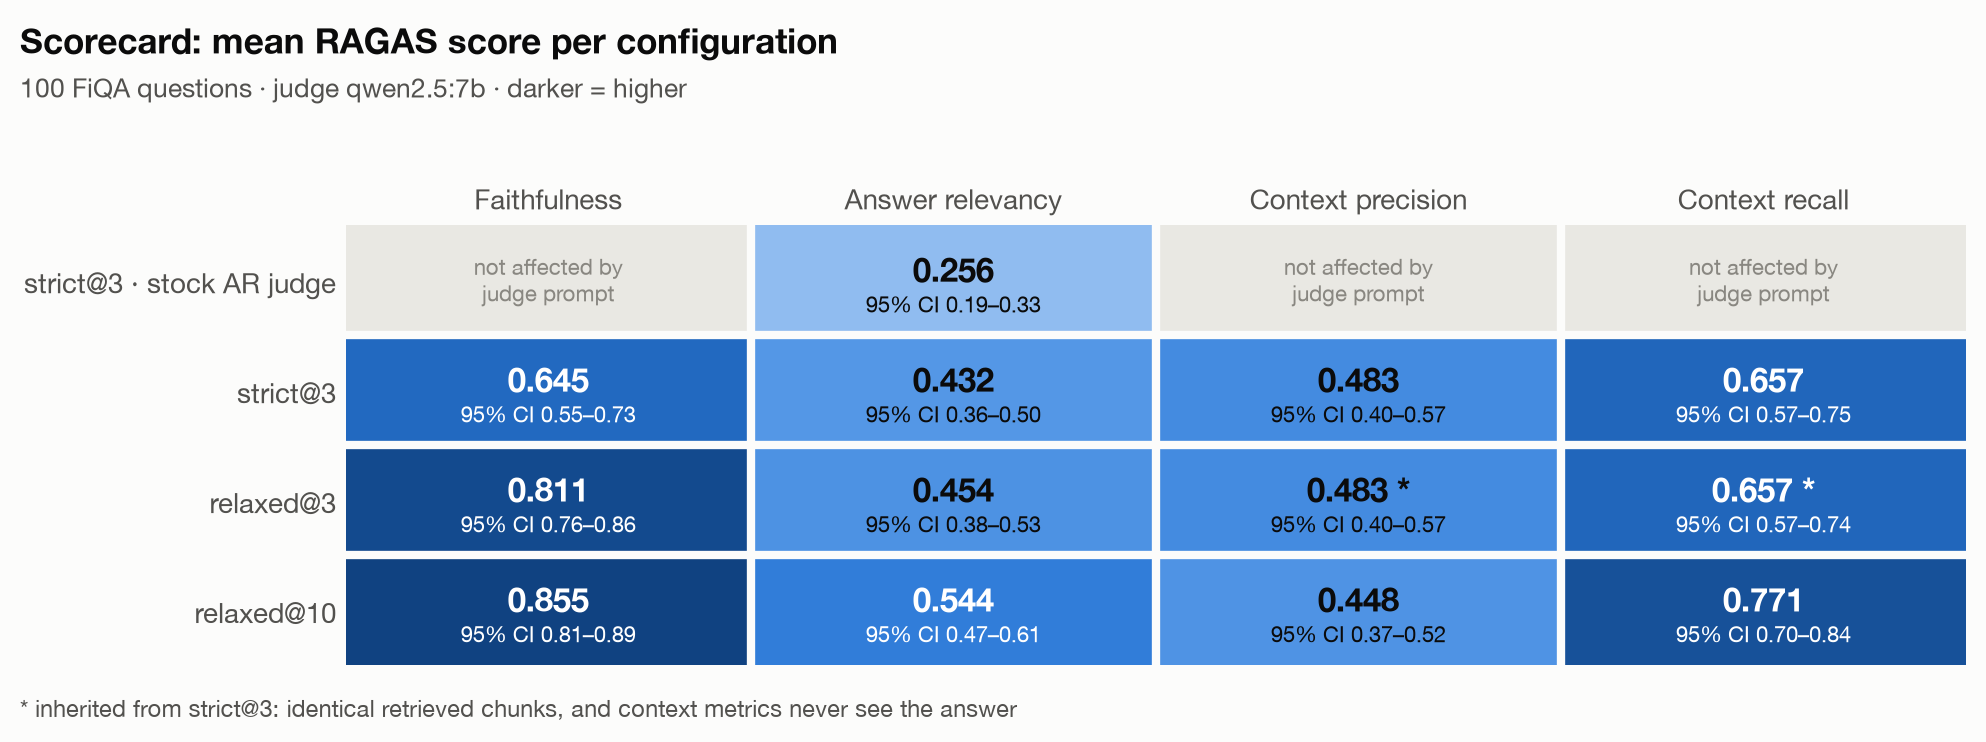

,Faithfulness,Answer relevancy,Context precision,Context recall
strict@3 · stock AR judge,—,"0.256 [0.186, 0.329]",—,—
strict@3,"0.645 [0.555, 0.731]","0.432 [0.357, 0.504]","0.483 [0.396, 0.572]","0.657 [0.567, 0.746]"
relaxed@3,"0.811 [0.759, 0.859]","0.454 [0.377, 0.527]","0.483 [0.396, 0.572] *","0.657 [0.568, 0.744] *"
relaxed@10,"0.855 [0.813, 0.891]","0.544 [0.471, 0.613]","0.448 [0.372, 0.521]","0.771 [0.695, 0.844]"


In [7]:
CONFIGS = [STOCK, *PATH]
cells = {}
for cfg in CONFIGS:
    for m in METRICS:
        if (cfg, m) in per_q:
            cells[(cfg, m)] = bootstrap_ci(per_q[(cfg, m)])

fig, ax = plt.subplots(figsize=(10, 3.7))
grid = np.full((len(CONFIGS), len(METRICS)), np.nan)
for (cfg, m), (mean, _, _) in cells.items():
    grid[CONFIGS.index(cfg), METRICS.index(m)] = mean
ax.imshow(np.ma.masked_invalid(grid), cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for i, cfg in enumerate(CONFIGS):
    for j, m in enumerate(METRICS):
        if (cfg, m) not in cells:
            ax.text(j, i, "not affected by\njudge prompt", ha="center", va="center", fontsize=8, color=MUTED)
            continue
        mean, lo, hi = cells[(cfg, m)]
        color = ink_for(SEQ(mean))
        star = " *" if (cfg, m) in INHERITED else ""
        ax.text(j, i - 0.1, f"{mean:.3f}{star}", ha="center", va="center", fontsize=12, fontweight="bold", color=color)
        ax.text(j, i + 0.22, f"95% CI {lo:.2f}–{hi:.2f}", ha="center", va="center", fontsize=8, color=color)
ax.set_xticks(range(len(METRICS)), [SHORT[m] for m in METRICS])
ax.set_yticks(range(len(CONFIGS)), CONFIGS)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for k in range(1, len(CONFIGS)):                     # surface-colored gaps between cells
    ax.axhline(k - 0.5, color=SURFACE, lw=3)
for k in range(1, len(METRICS)):
    ax.axvline(k - 0.5, color=SURFACE, lw=3)
fig.text(0.012, 0.02, "* inherited from strict@3: identical retrieved chunks, and context metrics never see the answer",
         fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.05, 1, header(fig, "Scorecard: mean RAGAS score per configuration",
                                         "100 FiQA questions · judge qwen2.5:7b · darker = higher")))
plt.show()

scorecard = pd.DataFrame(
    {SHORT[m]: {cfg: (f"{cells[(cfg, m)][0]:.3f}  [{cells[(cfg, m)][1]:.3f}, {cells[(cfg, m)][2]:.3f}]"
                      + (" *" if (cfg, m) in INHERITED else "")) if (cfg, m) in cells else "—"
                for cfg in CONFIGS} for m in METRICS}
)
scorecard

Reading the scorecard:

* Every metric is at its highest in **relaxed@10**, except context precision, which is highest at `top_k = 3`.
* The 95% intervals are wide, about ±0.07–0.09, because there are only 100 questions and many scores are exactly 0 or 1 (§12). Overlapping intervals here do **not** mean "no difference": every comparison uses the same questions, so the paired deltas in §6 are much tighter.

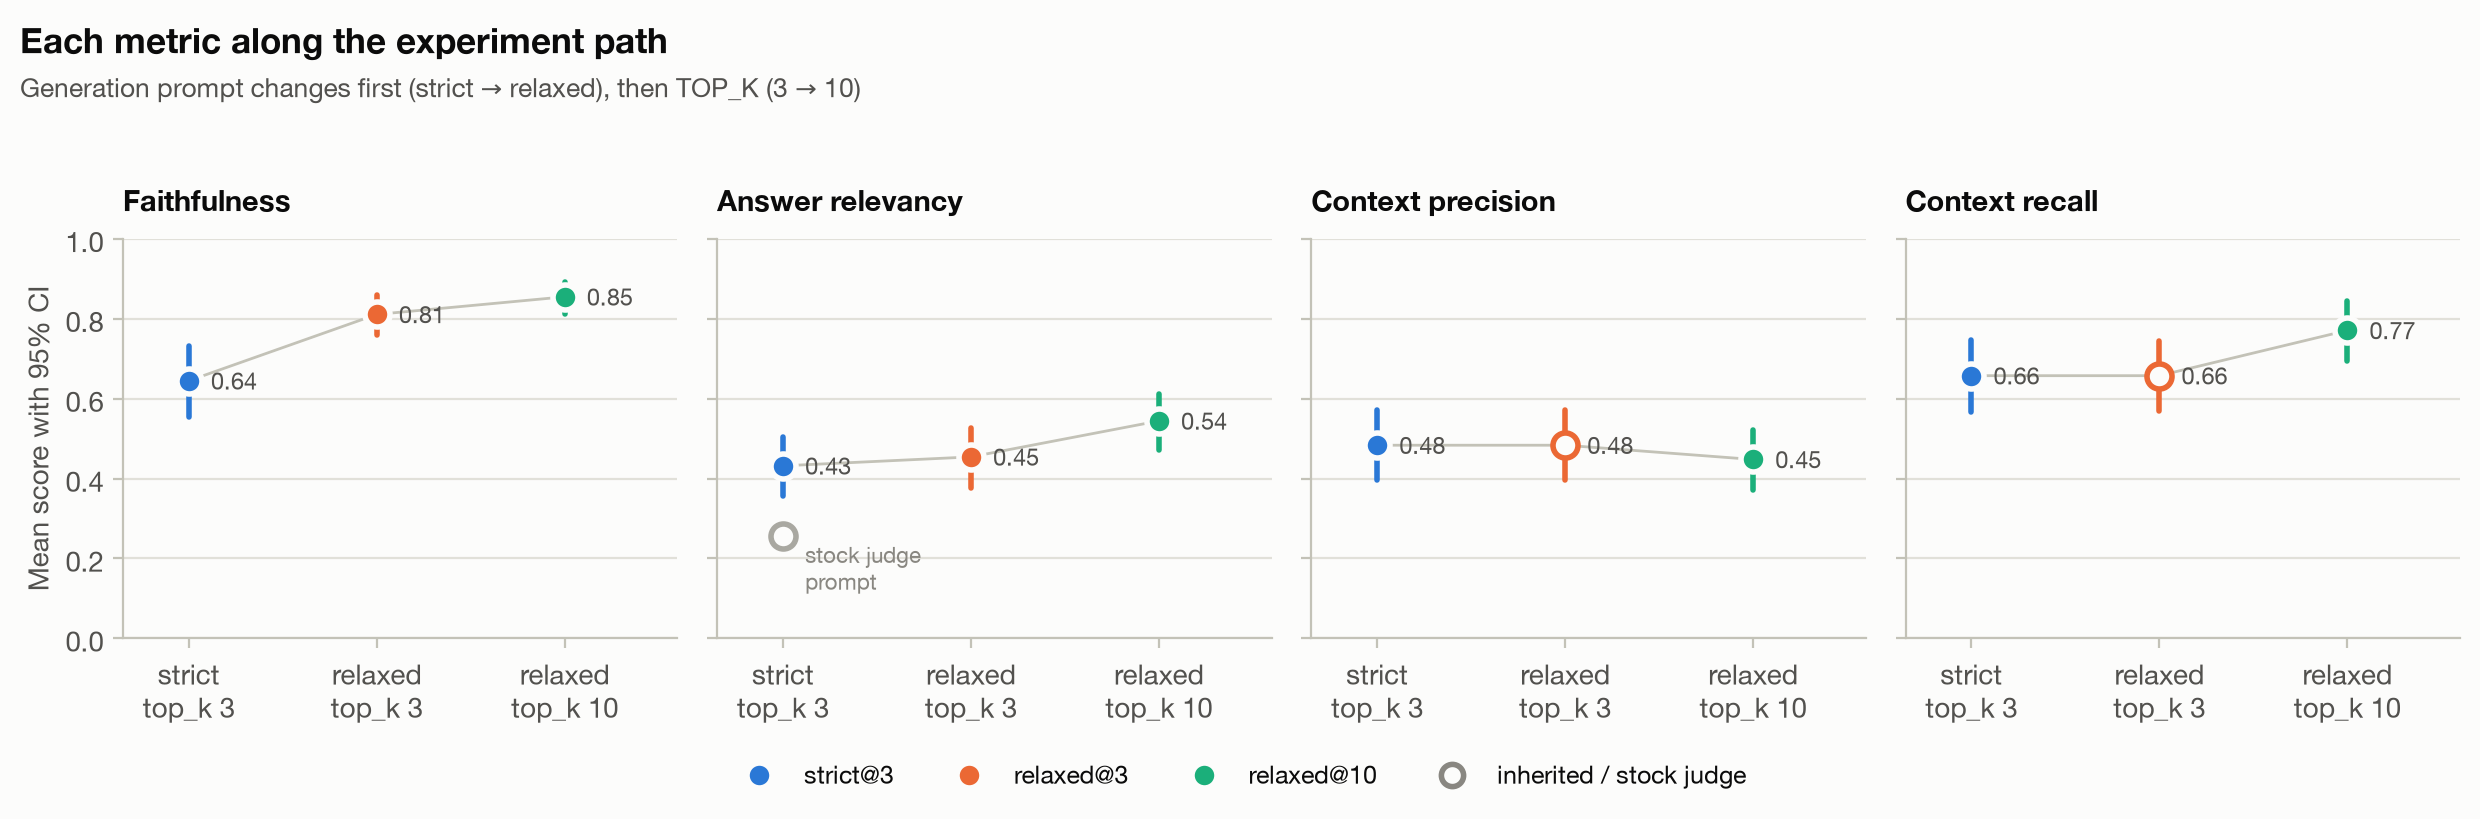

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 4.1), sharey=True)
for ax, m in zip(axes, METRICS):
    pts = []
    for x, cfg in enumerate(PATH):
        mean, lo, hi = cells[(cfg, m)]
        inherited = (cfg, m) in INHERITED
        ax.plot([x, x], [lo, hi], color=RUN_COLORS[cfg], lw=2, solid_capstyle="round", zorder=2)
        ax.plot(x, mean, "o", ms=9, mew=2, zorder=3,
                mfc=SURFACE if inherited else RUN_COLORS[cfg], mec=RUN_COLORS[cfg] if inherited else SURFACE)
        ax.annotate(f"{mean:.2f}", (x, mean), xytext=(8, 0), textcoords="offset points", va="center",
                    fontsize=8.5, color=INK_2)
        pts.append((x, mean))
    ax.plot(*zip(*pts), color=AXIS, lw=1, zorder=1)
    if m == "answer_relevancy":
        mean = cells[(STOCK, m)][0]
        ax.plot(0, mean, "o", ms=9, mew=2, mfc=SURFACE, mec=STOCK_GRAY, zorder=3)
        ax.annotate("stock judge\nprompt", (0, mean), xytext=(8, -2), textcoords="offset points", va="top",
                    fontsize=8, color=MUTED)
    ax.set_title(SHORT[m])
    ax.set_xticks(range(3), ["strict\ntop_k 3", "relaxed\ntop_k 3", "relaxed\ntop_k 10"])
    ax.set_xlim(-0.35, 2.6)
    ax.grid(axis="x", visible=False)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Mean score with 95% CI")
handles = [Line2D([], [], marker="o", ls="", ms=8, mfc=RUN_COLORS[c], mec=SURFACE, label=c) for c in PATH]
handles += [Line2D([], [], marker="o", ls="", ms=8, mfc=SURFACE, mec=MUTED, mew=2, label="inherited / stock judge")]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=(0, 0.07, 1, header(fig, "Each metric along the experiment path",
                                         "Generation prompt changes first (strict → relaxed), then TOP_K (3 → 10)")))
plt.show()

## 6. How each constant changed the metrics

Each row compares two configurations that differ in exactly one constant, **on the same 100 questions**. The delta is the mean of the per-question differences (after − before). Its 95% CI comes from a paired bootstrap, which removes question-to-question difficulty from the noise. A filled dot means the CI excludes 0.

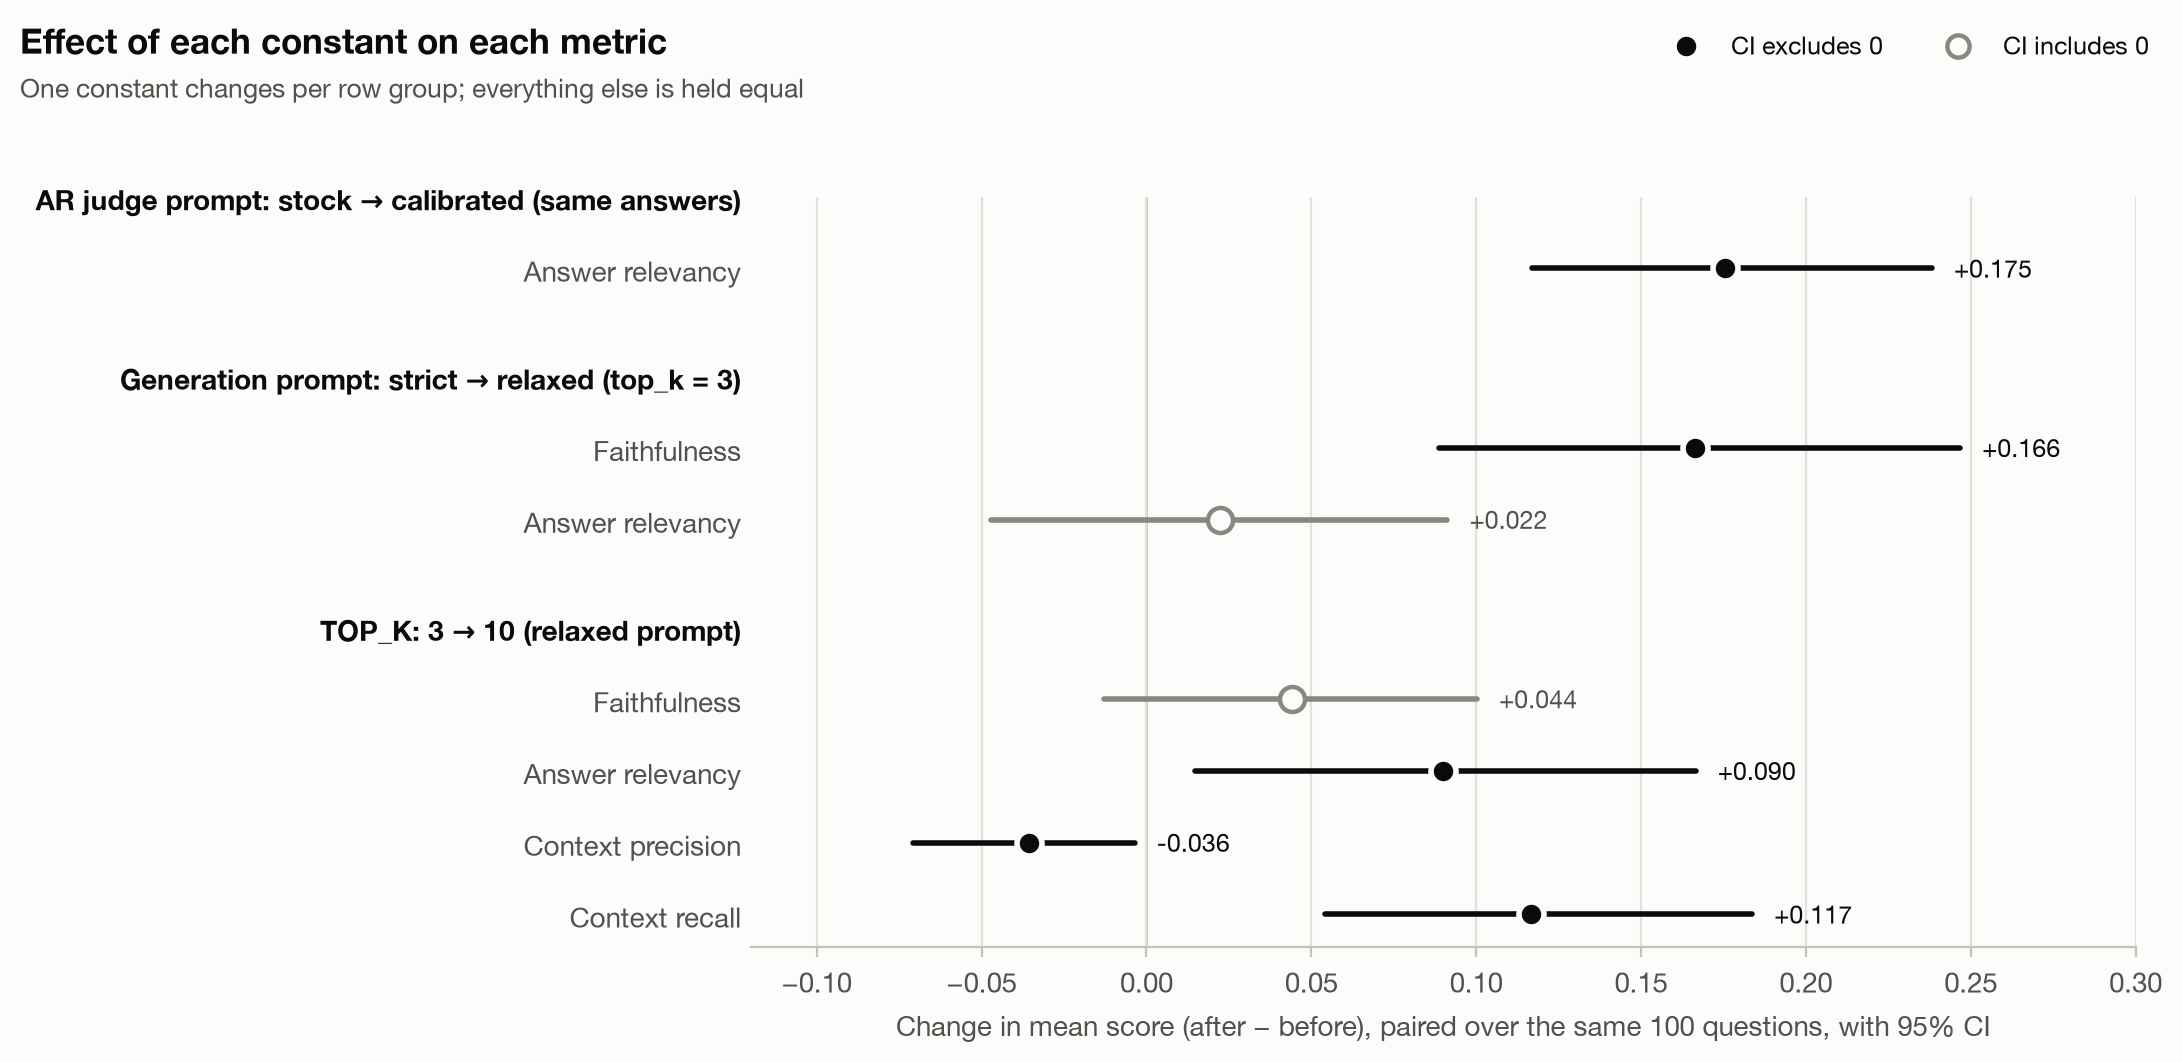

,constant changed,metric,before,after,delta,CI low,CI high,questions up,down,unchanged,n
0,AR judge prompt: stock → calibrated (same answers),Answer relevancy,0.256,0.432,0.175,0.117,0.238,40,13,47,100
1,Generation prompt: strict → relaxed (top_k = 3),Faithfulness,0.645,0.811,0.166,0.089,0.247,43,25,32,100
2,Generation prompt: strict → relaxed (top_k = 3),Answer relevancy,0.432,0.454,0.022,-0.047,0.091,38,29,33,100
3,TOP_K: 3 → 10 (relaxed prompt),Faithfulness,0.811,0.855,0.044,-0.013,0.100,39,33,28,100
4,TOP_K: 3 → 10 (relaxed prompt),Answer relevancy,0.454,0.544,0.090,0.015,0.167,45,29,26,100
5,TOP_K: 3 → 10 (relaxed prompt),Context precision,0.483,0.448,-0.036,-0.071,-0.004,13,22,65,100
6,TOP_K: 3 → 10 (relaxed prompt),Context recall,0.657,0.771,0.117,0.054,0.184,20,13,66,99


In [9]:
EFFECTS = [
    ("AR judge prompt: stock → calibrated (same answers)", "answer_relevancy", STOCK, "strict@3"),
    ("Generation prompt: strict → relaxed (top_k = 3)", "faithfulness", "strict@3", "relaxed@3"),
    ("Generation prompt: strict → relaxed (top_k = 3)", "answer_relevancy", "strict@3", "relaxed@3"),
    ("TOP_K: 3 → 10 (relaxed prompt)", "faithfulness", "relaxed@3", "relaxed@10"),
    ("TOP_K: 3 → 10 (relaxed prompt)", "answer_relevancy", "relaxed@3", "relaxed@10"),
    ("TOP_K: 3 → 10 (relaxed prompt)", "context_precision", "relaxed@3", "relaxed@10"),
    ("TOP_K: 3 → 10 (relaxed prompt)", "context_recall", "relaxed@3", "relaxed@10"),
]
rows = []
for variable, m, before, after in EFFECTS:
    d = (per_q[(after, m)] - per_q[(before, m)]).dropna()
    delta, lo, hi = bootstrap_ci(d)
    rows.append({"constant changed": variable, "metric": SHORT[m],
                 "before": per_q[(before, m)].mean(), "after": per_q[(after, m)].mean(),
                 "delta": delta, "CI low": lo, "CI high": hi,
                 "questions up": int((d > 0).sum()), "down": int((d < 0).sum()), "unchanged": int((d == 0).sum()),
                 "n": len(d)})
effects = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(11, 5.4))
y, ticks, labels, headers = 0, [], [], []
for variable, grp in effects.groupby("constant changed", sort=False):
    ticks.append(y); labels.append(variable); headers.append(y); y += 1
    for _, r in grp.iterrows():
        sig = r["CI low"] > 0 or r["CI high"] < 0
        col = INK if sig else MUTED
        ax.plot([r["CI low"], r["CI high"]], [y, y], color=col, lw=2, solid_capstyle="round")
        ax.plot(r.delta, y, "o", ms=9, mew=2 if sig else 1.6, mfc=INK if sig else SURFACE, mec=SURFACE if sig else MUTED)
        ax.annotate(f"{r.delta:+.3f}", (r["CI high"], y), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK if sig else INK_2)
        ticks.append(y); labels.append("    " + r.metric); y += 1
    y += 0.5
ax.set_yticks(ticks, labels)
for t, pos in zip(ax.get_yticklabels(), ticks):
    if pos in headers:
        t.set_fontweight("bold"); t.set_color(INK)
ax.tick_params(axis="y", length=0)
ax.invert_yaxis()
ax.axvline(0, color=AXIS, lw=1, zorder=0)
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_xlim(-0.12, 0.3)
ax.set_xlabel("Change in mean score (after − before), paired over the same 100 questions, with 95% CI")
fig.legend(handles=[Line2D([], [], marker="o", ls="", ms=8, mfc=INK, mec=SURFACE, label="CI excludes 0"),
                    Line2D([], [], marker="o", ls="", ms=8, mfc=SURFACE, mec=MUTED, mew=1.6, label="CI includes 0")],
           loc="upper right", bbox_to_anchor=(0.99, 0.985), ncol=2)
fig.tight_layout(rect=(0, 0, 1, header(fig, "Effect of each constant on each metric",
                                       "One constant changes per row group; everything else is held equal")))
plt.show()

effects.round(3)

Reading the effects:

| Constant | What it did |
|---|---|
| **AR judge prompt** | The largest single effect (+0.175), and it is purely a change in **measurement**: the answers are byte-identical. Answer-relevancy numbers from the two judge prompts are not comparable. Every comparison after this one uses the calibrated prompt. |
| **Generation prompt** | Faithfulness +0.166 (significant). Answer relevancy +0.022 (not significant). §8 shows that the faithfulness gain comes from removing refusals, and that answers which both prompts gave got slightly *less* faithful. |
| **`TOP_K`** | Context recall +0.117 and answer relevancy +0.090 (both significant). Faithfulness +0.044 (not significant). Context precision −0.036 (significant, but only just: the CI upper bound is −0.004). 65 to 66 questions have unchanged context scores; the gains are concentrated in the questions whose reference only appears at ranks 4–10 (§9). |

## 7. Variable 1: the answer-relevancy judge prompt

Runs A and B score the **same 100 answers**. Only the judge's noncommittal instructions differ. Any change is therefore caused by the judge, not by the pipeline.

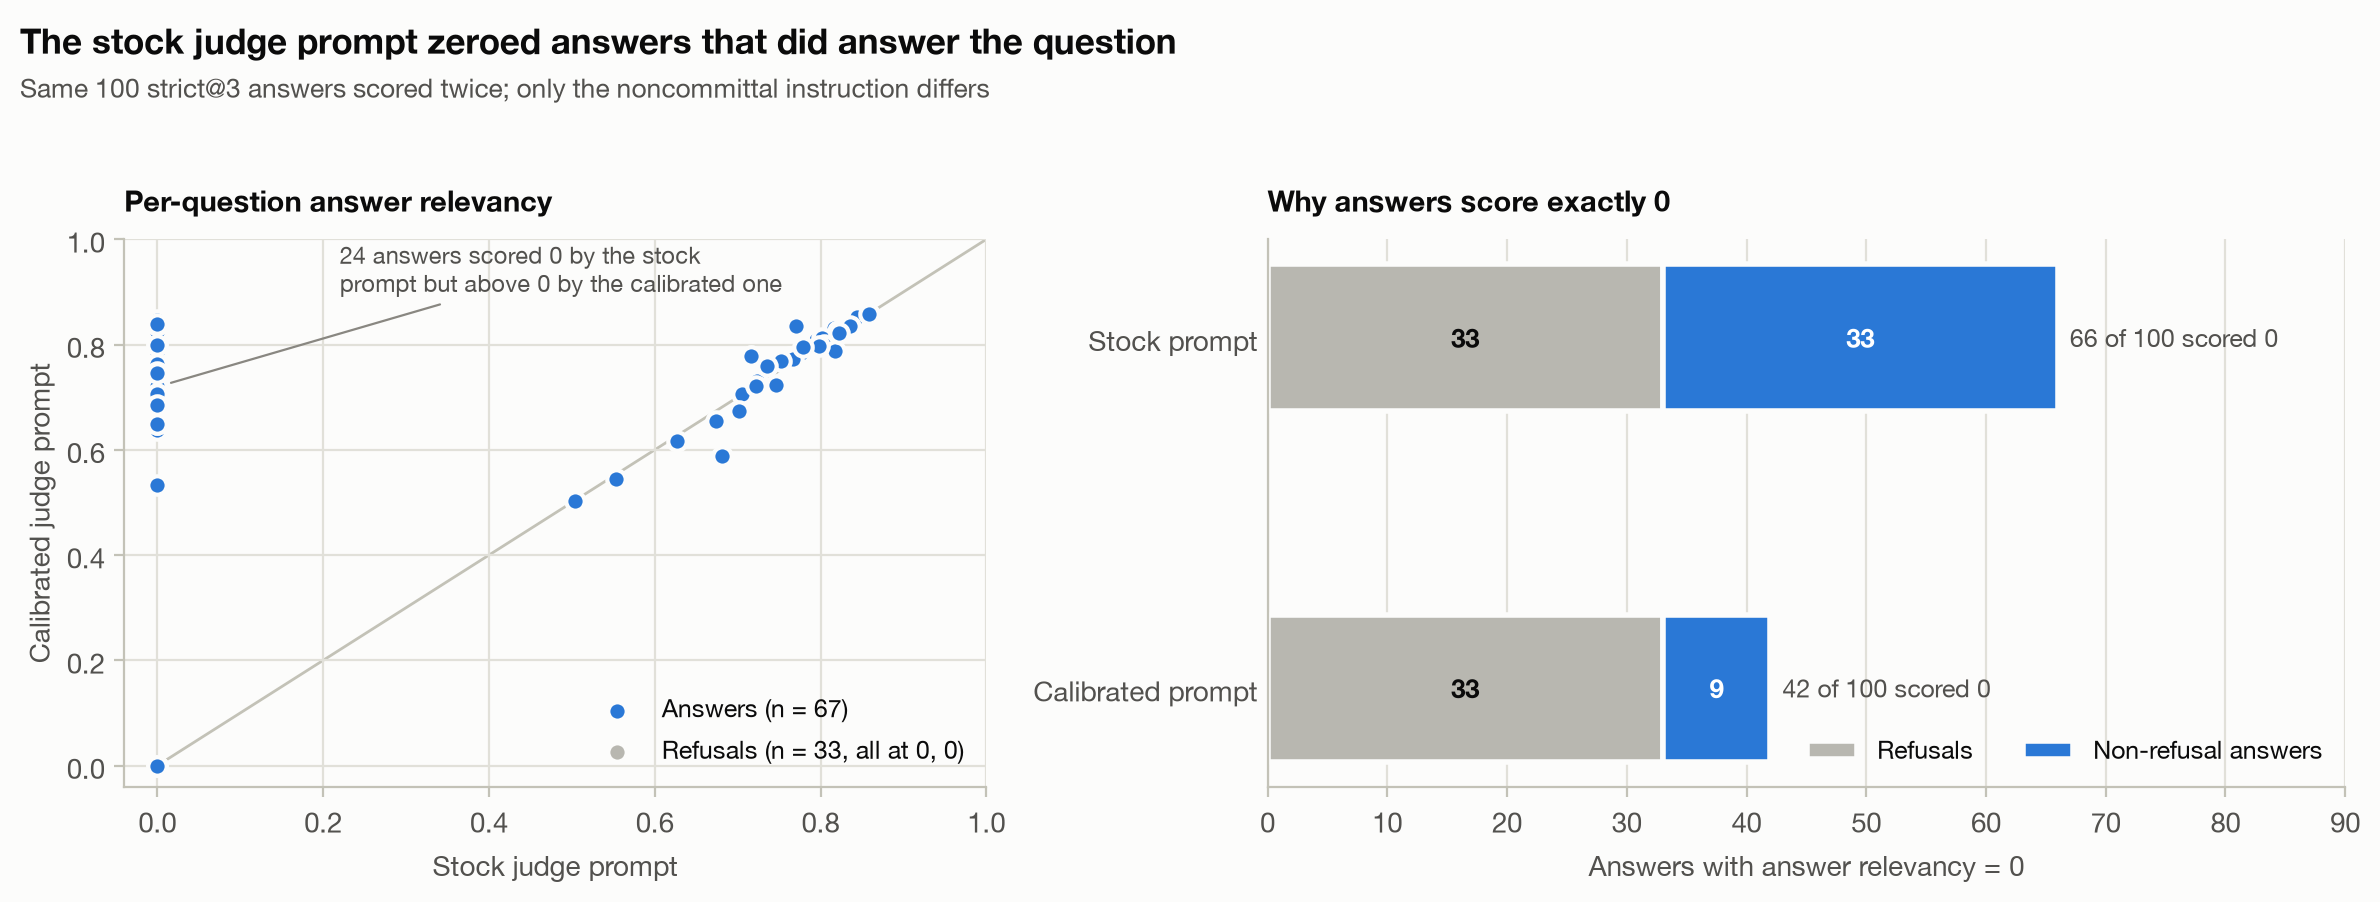

,stock prompt,calibrated prompt
mean answer relevancy,0.256,0.432
answers scored 0,66.000,42.000
mean over non-refusals,0.383,0.644


In [10]:
stock = per_q[(STOCK, "answer_relevancy")]
calib = per_q[("strict@3", "answer_relevancy")]
refused = q["strict refused"]
rescued = (~refused) & (stock == 0) & (calib > 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax1.plot([0, 1], [0, 1], color=AXIS, lw=1, zorder=0)
ax1.scatter(stock[~refused], calib[~refused], s=44, color=RUN_COLORS["strict@3"], edgecolor=SURFACE, lw=1.5,
            label=f"Answers (n = {(~refused).sum()})", zorder=3)
ax1.scatter(stock[refused], calib[refused], s=44, color=ANSWER_TYPE_COLORS["Refused"], edgecolor=SURFACE, lw=1.5,
            label=f"Refusals (n = {refused.sum()}, all at 0, 0)", zorder=2)
ax1.annotate(f"{rescued.sum()} answers scored 0 by the stock\nprompt but above 0 by the calibrated one",
             xy=(0.01, calib[rescued].median()), xytext=(0.22, 0.9), fontsize=8.5, color=INK_2,
             arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax1.set(xlim=(-0.04, 1), ylim=(-0.04, 1), xlabel="Stock judge prompt", ylabel="Calibrated judge prompt")
ax1.set_title("Per-question answer relevancy")
ax1.legend(loc="lower right")

zero = pd.DataFrame({
    "Refusals": [(stock[refused] == 0).sum(), (calib[refused] == 0).sum()],
    "Non-refusal answers": [(stock[~refused] == 0).sum(), (calib[~refused] == 0).sum()],
}, index=["Stock prompt", "Calibrated prompt"])
left = np.zeros(2)
for col, color in [("Refusals", ANSWER_TYPE_COLORS["Refused"]), ("Non-refusal answers", RUN_COLORS["strict@3"])]:
    bars = ax2.barh(zero.index, zero[col], left=left, height=0.42, color=color, edgecolor=SURFACE, lw=2, label=col)
    for b, v in zip(bars, zero[col]):
        if v >= 5:
            ax2.text(b.get_x() + b.get_width() / 2, b.get_y() + b.get_height() / 2, str(v), ha="center", va="center",
                     fontsize=9.5, fontweight="bold", color=ink_for(to_rgba(color)))
    left += zero[col].to_numpy()
for i, total in enumerate(left):
    ax2.text(total + 1, i, f"{int(total)} of 100 scored 0", va="center", fontsize=9, color=INK_2)
ax2.invert_yaxis()
ax2.set_xlim(0, 90)
ax2.set_xlabel("Answers with answer relevancy = 0")
ax2.set_title("Why answers score exactly 0")
ax2.grid(axis="y", visible=False)
ax2.tick_params(axis="y", length=0)
ax2.legend(loc="lower right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, header(fig, "The stock judge prompt zeroed answers that did answer the question",
                                       "Same 100 strict@3 answers scored twice; only the noncommittal instruction differs")))
plt.show()

pd.DataFrame({"stock prompt": [stock.mean(), (stock == 0).sum(), stock[~refused].mean()],
              "calibrated prompt": [calib.mean(), (calib == 0).sum(), calib[~refused].mean()]},
             index=["mean answer relevancy", "answers scored 0", "mean over non-refusals"])

**Takeaways**

* Answer relevancy multiplies the embedding similarity by (1 − noncommittal), so one wrong flag sends a good answer straight to 0. With the stock prompt, the 7B judge flagged 33 non-refusal answers; the notes in `run_eval.py` trace this to answers that contain a caveat. With the calibrated prompt it flagged 9.
* The 33 real refusals score 0 under both prompts, which is correct.
* The calibrated prompt is the right baseline for a 7B judge. It does not inflate scores: points barely move unless they started at 0. Its examples are generic, so it is not fitted to this golden set.
* **Do not compare answer relevancy across judge prompts.** Run A's 0.256 is meaningful only next to run B's 0.432.

## 8. Variable 2: generation prompt (strict → relaxed, `top_k = 3`)

Both configurations retrieved the same three chunks for every question, so any difference comes from how the model answers.

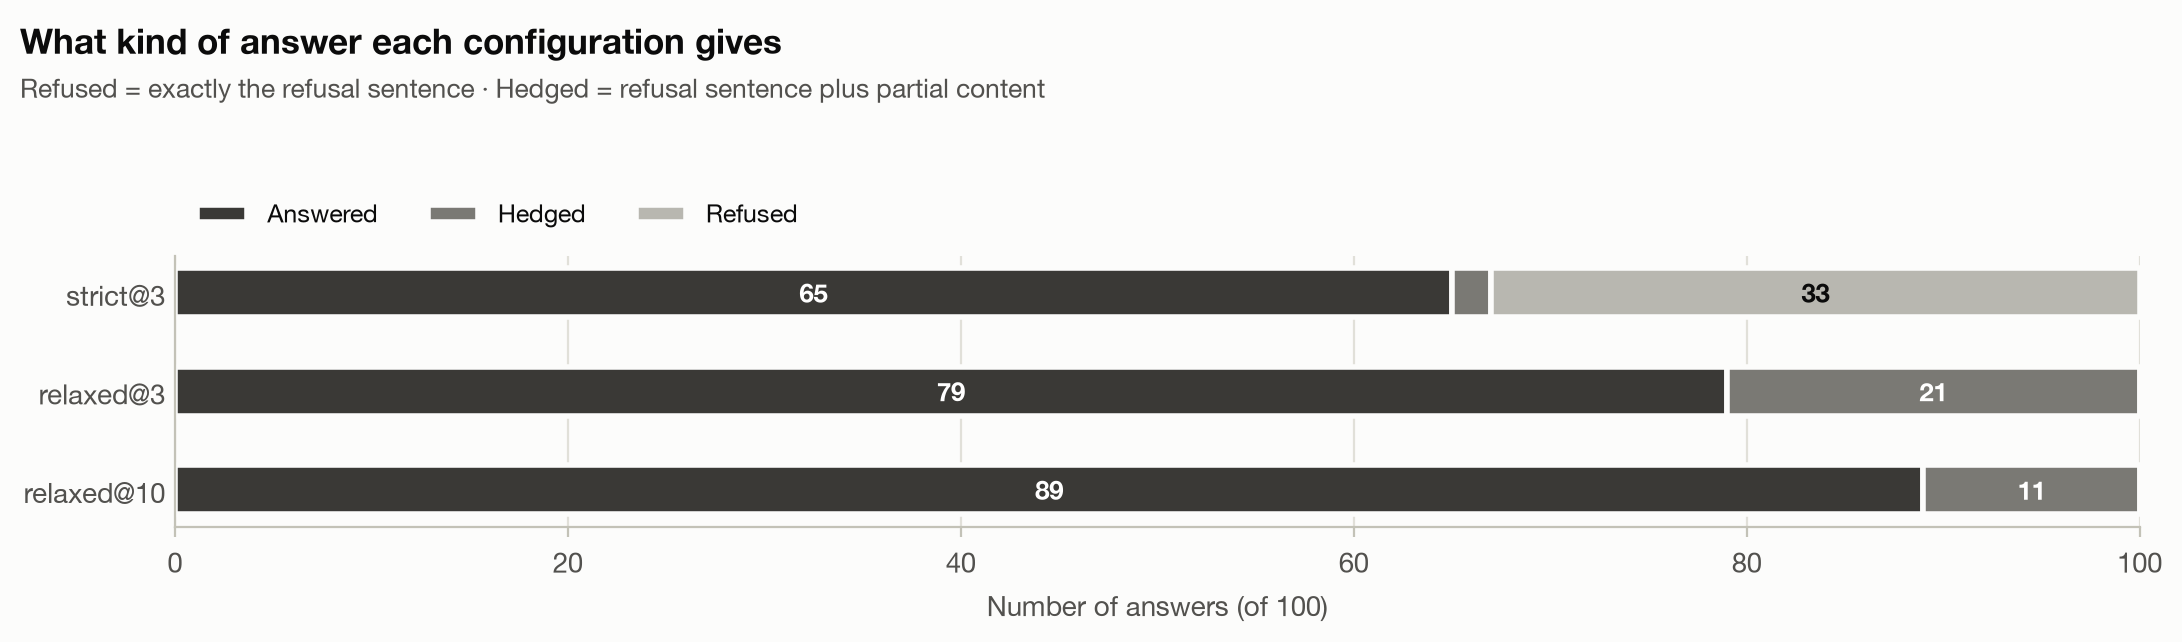

,Answered,Hedged,Refused
strict@3,65,2,33
relaxed@3,79,21,0
relaxed@10,89,11,0


In [11]:
types = pd.DataFrame({cfg: q[f"type {cfg}"].value_counts() for cfg in PATH}).reindex(
    ["Answered", "Hedged", "Refused"]).fillna(0).astype(int).T

fig, ax = plt.subplots(figsize=(11, 3.3))
left = np.zeros(len(PATH))
for t in types.columns:
    bars = ax.barh(types.index, types[t], left=left, height=0.5, color=ANSWER_TYPE_COLORS[t],
                   edgecolor=SURFACE, lw=2, label=t)
    for b, v in zip(bars, types[t]):
        if v >= 5:
            ax.text(b.get_x() + b.get_width() / 2, b.get_y() + b.get_height() / 2, str(v), ha="center", va="center",
                    fontsize=9.5, fontweight="bold", color=ink_for(to_rgba(ANSWER_TYPE_COLORS[t])))
    left += types[t].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Number of answers (of 100)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=3)
fig.tight_layout(rect=(0, 0, 1, header(fig, "What kind of answer each configuration gives",
                                       "Refused = exactly the refusal sentence · Hedged = refusal sentence plus partial content")))
plt.show()
types

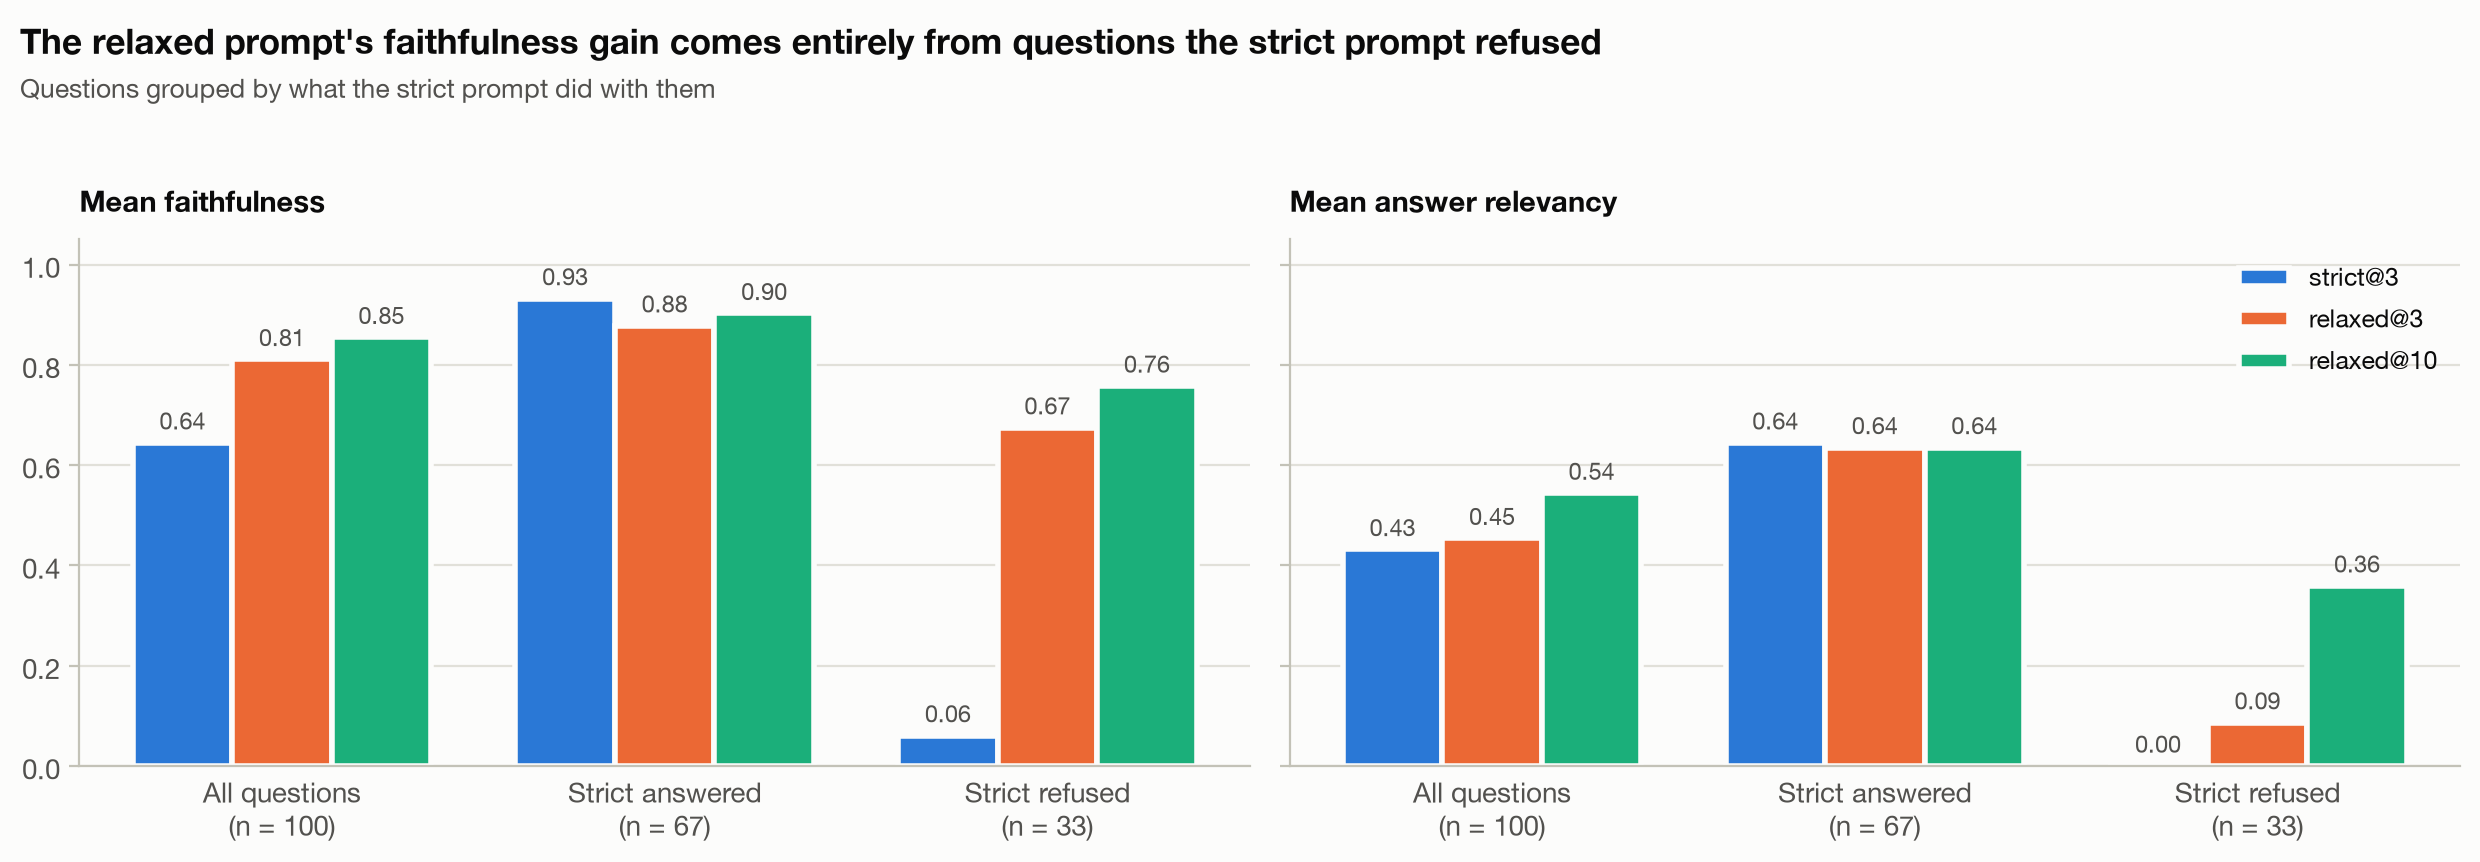

Faithfulness                                Answer relevancy  \
           All questions Strict answered Strict refused    All questions   
strict@3           0.645           0.932          0.061            0.432   
relaxed@3          0.811           0.878          0.675            0.454   
relaxed@10         0.855           0.903          0.758            0.544   

                                           
           Strict answered Strict refused  
strict@3             0.644          0.000  
relaxed@3            0.635          0.086  
relaxed@10           0.635          0.359

In [12]:
groups = {"All questions": pd.Series(True, index=q.index),
          "Strict answered": ~q["strict refused"],
          "Strict refused": q["strict refused"]}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
w = 0.26
for ax, m in zip(axes, ["faithfulness", "answer_relevancy"]):
    for k, cfg in enumerate(PATH):
        vals = [per_q.loc[mask, (cfg, m)].mean() for mask in groups.values()]
        bars = ax.bar(np.arange(3) + (k - 1) * w, vals, width=w, color=RUN_COLORS[cfg], edgecolor=SURFACE, lw=2,
                      label=cfg)
        label_bars(ax, bars)
    ax.set_xticks(range(3), [f"{g}\n(n = {mask.sum()})" for g, mask in groups.items()])
    ax.set_title(f"Mean {SHORT[m].lower()}")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylim(0, 1.05)
axes[1].legend(loc="upper right")
fig.tight_layout(rect=(0, 0, 1, header(fig, "The relaxed prompt's faithfulness gain comes entirely from questions the strict prompt refused",
                                       "Questions grouped by what the strict prompt did with them")))
plt.show()

pd.DataFrame({
    (SHORT[m], g): {cfg: per_q.loc[mask, (cfg, m)].mean() for cfg in PATH}
    for m in ["faithfulness", "answer_relevancy"] for g, mask in groups.items()
}).round(3)

**What changed and why**

* **Refusals disappeared, but hedging took their place.** The strict prompt refused 33 questions outright. The relaxed prompt never gives the bare refusal, but 21 of its answers still contain the refusal sentence along with partial content (14 of them open with it).
* **The faithfulness gain is a composition effect.** On the 33 questions the strict prompt refused, faithfulness rose from 0.06 to 0.68, because a refusal is almost always scored 0 while a partial answer drawn from the chunks scores high. On the 67 questions the strict prompt did not refuse, faithfulness fell from 0.932 to 0.878. Relaxed answers are about 2.5× longer (154 vs 62 words, §10), and longer answers give the judge more statements that can fail the check.
* **Answer relevancy barely moved, because hedges are scored as refusals.** The calibrated judge sets noncommittal = 1 when an answer says "the information is not provided", so all 21 hedged answers score 0. Most of the other 20 relaxed answers that score 0 (18 of them) say that the context lacks the answer before giving partial information. On the strict-refused questions, answer relevancy rose only from 0 to 0.09.
* **Not every strict refusal was a retrieval failure.** In 16 of the 33 refusals the question's own reference was among the 3 retrieved chunks. The strict prompt refused even though the answer was in front of it, which is what motivated the relaxed variant.

Example: one question under the three configurations.

In [13]:
cands = q[q["strict refused"] & (q.gold_rank <= 3) & q["type relaxed@3"].eq("Answered")
          & (C.faithfulness >= 0.9) & (C.answer_relevancy >= 0.5)]
qid = cands.index[0]
wrap = lambda s, n=600: textwrap.fill(s if len(s) <= n else s[:n] + " …", 110, initial_indent="    ", subsequent_indent="    ")
print(f"{qid}: {q.question[qid]}")
print(f"Reference document rank among retrieved chunks: {int(q.gold_rank[qid])}\n")
print("Reference answer (truncated):\n" + wrap(A.reference[qid], 400) + "\n")
for cfg, df in [("strict@3", A), ("relaxed@3", C), ("relaxed@10", D)]:
    f, ar = per_q.loc[qid, (cfg, "faithfulness")], per_q.loc[qid, (cfg, "answer_relevancy")]
    print(f"── {cfg}   faithfulness {f:.2f} · answer relevancy {ar:.2f}")
    print(wrap(df.response[qid]) + "\n")

fiqa_0004: Can increasing my tax withholding from my full-time job cover FICA taxes for my freelance work?
Reference document rank among retrieved chunks: 2

Reference answer (truncated):
    Technically you owe 'self-employment' taxes not FICA taxes because they are imposed under a different law,
    SECA. However, since SE taxes are by design exactly the same rates as combining the two halves of FICA
    (employer and employee) it is quite reasonable to treat them as equivalent. SE taxes (and income tax also)
    are based on your net self-employment income, after deducting business expenses (bu …

── strict@3   faithfulness 0.00 · answer relevancy 0.00
    I don't know based on the provided documents.

── relaxed@3   faithfulness 1.00 · answer relevancy 0.71
    Based on the provided context, increasing your tax withholding from your full-time job might not cover
    FICA taxes for your freelance work. The context mentions that an employer withholds taxes by extrapolating
    your m

## 9. Variable 3: `TOP_K` (3 → 10, relaxed prompt)

### Retrieval: how often the reference document is retrieved

Retrieval is deterministic and the top 3 chunks are a prefix of the top 10 (§4). So the reference's rank in the top-10 list gives the exact hit rate for every `top_k` from 1 to 10 without re-running anything. This hit rate does not use the LLM judge.

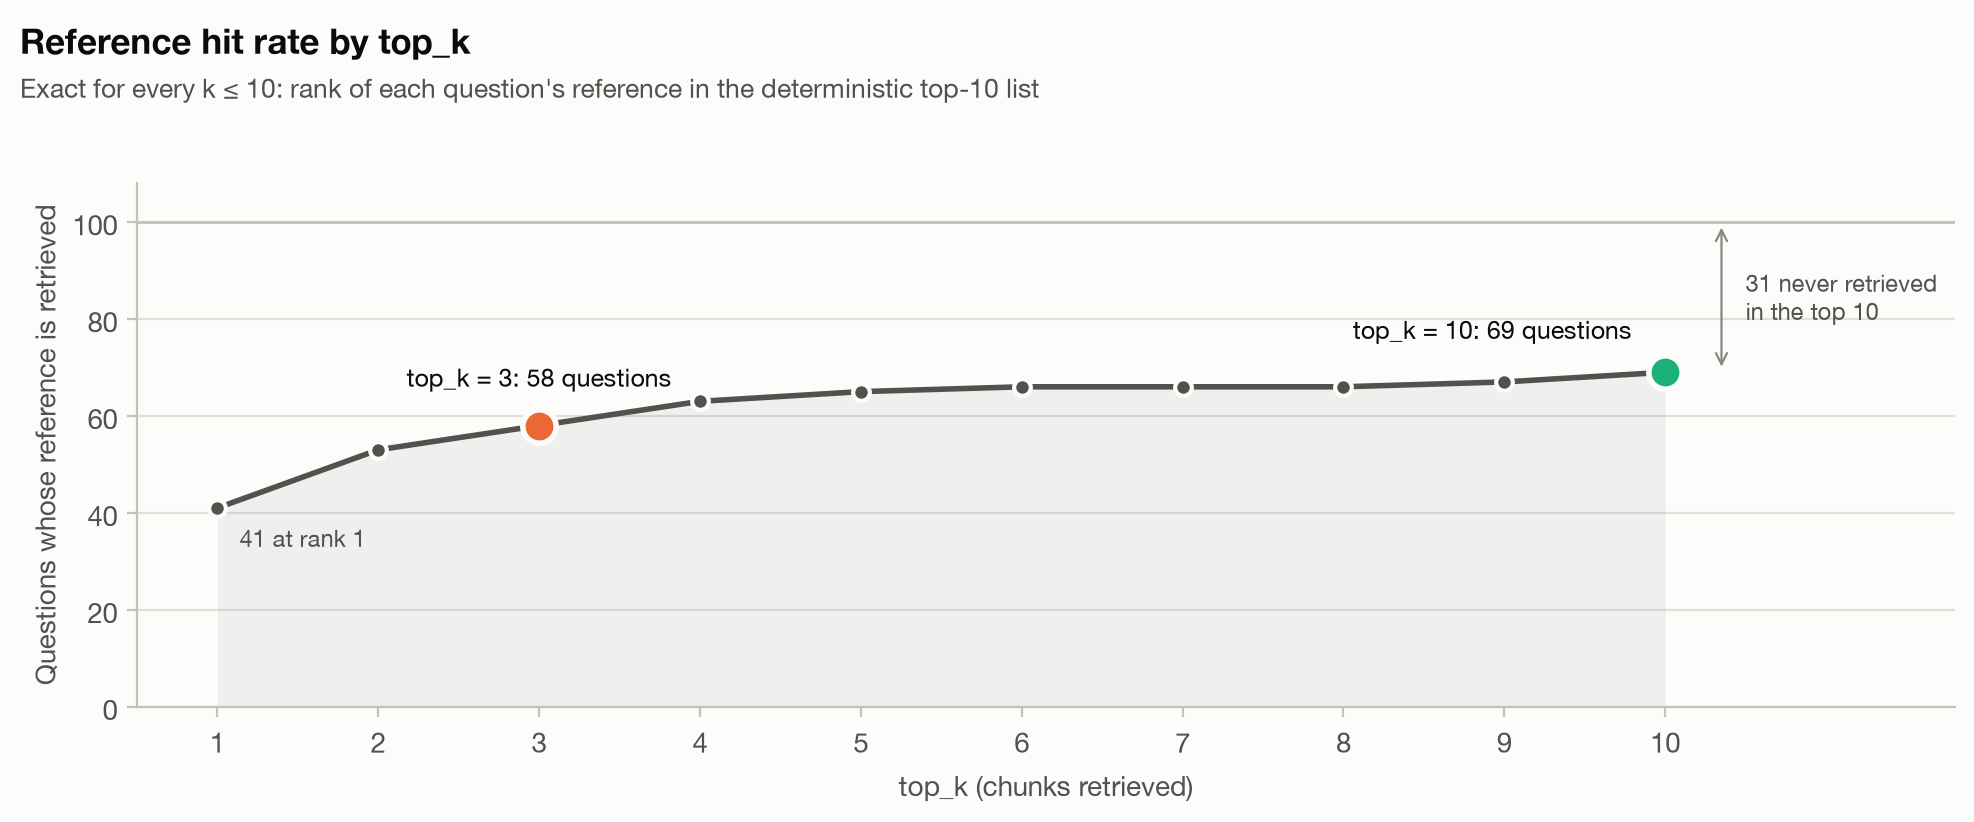

top_k,1,2,3,4,5,6,7,8,9,10
questions with reference retrieved,41,53,58,63,65,66,66,66,67,69


In [14]:
ks = np.arange(1, 11)
hits = np.array([(q.gold_rank <= k).sum() for k in ks])

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.fill_between(ks, hits, color=INK_2, alpha=0.07, lw=0)
ax.plot(ks, hits, color=INK_2, lw=2, marker="o", ms=6, mfc=INK_2, mec=SURFACE, mew=1.5, zorder=3)
for k, cfg in [(3, "relaxed@3"), (10, "relaxed@10")]:
    ax.plot(k, hits[k - 1], "o", ms=12, mfc=RUN_COLORS[cfg], mec=SURFACE, mew=2, zorder=4)
    ax.annotate(f"top_k = {k}: {hits[k - 1]} questions", (k, hits[k - 1]), xytext=(0, 14) if k < 10 else (-12, 12),
                textcoords="offset points", ha="center" if k < 10 else "right", fontsize=9, color=INK)
ax.annotate(f"{hits[0]} at rank 1", (1, hits[0]), xytext=(8, -14), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.axhline(100, color=AXIS, lw=1)
ax.annotate("", xy=(10.35, 100), xytext=(10.35, hits[-1]), arrowprops=dict(arrowstyle="<->", color=MUTED, lw=0.8))
ax.text(10.5, (100 + hits[-1]) / 2, f"{100 - hits[-1]} never retrieved\nin the top 10", va="center", fontsize=8.5, color=INK_2)
ax.set(xticks=ks, xlim=(0.5, 11.8), ylim=(0, 108), xlabel="top_k (chunks retrieved)",
       ylabel="Questions whose reference is retrieved")
ax.grid(axis="x", visible=False)
fig.tight_layout(rect=(0, 0, 1, header(fig, "Reference hit rate by top_k",
                                       "Exact for every k ≤ 10: rank of each question's reference in the deterministic top-10 list")))
plt.show()
pd.Series(hits, index=pd.Index(ks, name="top_k"), name="questions with reference retrieved").to_frame().T

* The top 1 already holds the reference for 41 questions. Going from 3 to 10 chunks adds 11, and 7 of those 11 arrive by k = 5. That suggests `top_k ≈ 5` may get most of the recall gain at lower cost; the README already gives 5 as the default.
* **31 questions never retrieve their reference, even at k = 10.** No generation-side change can fix these. Embedding, chunking, hybrid search or query rewriting would have to.

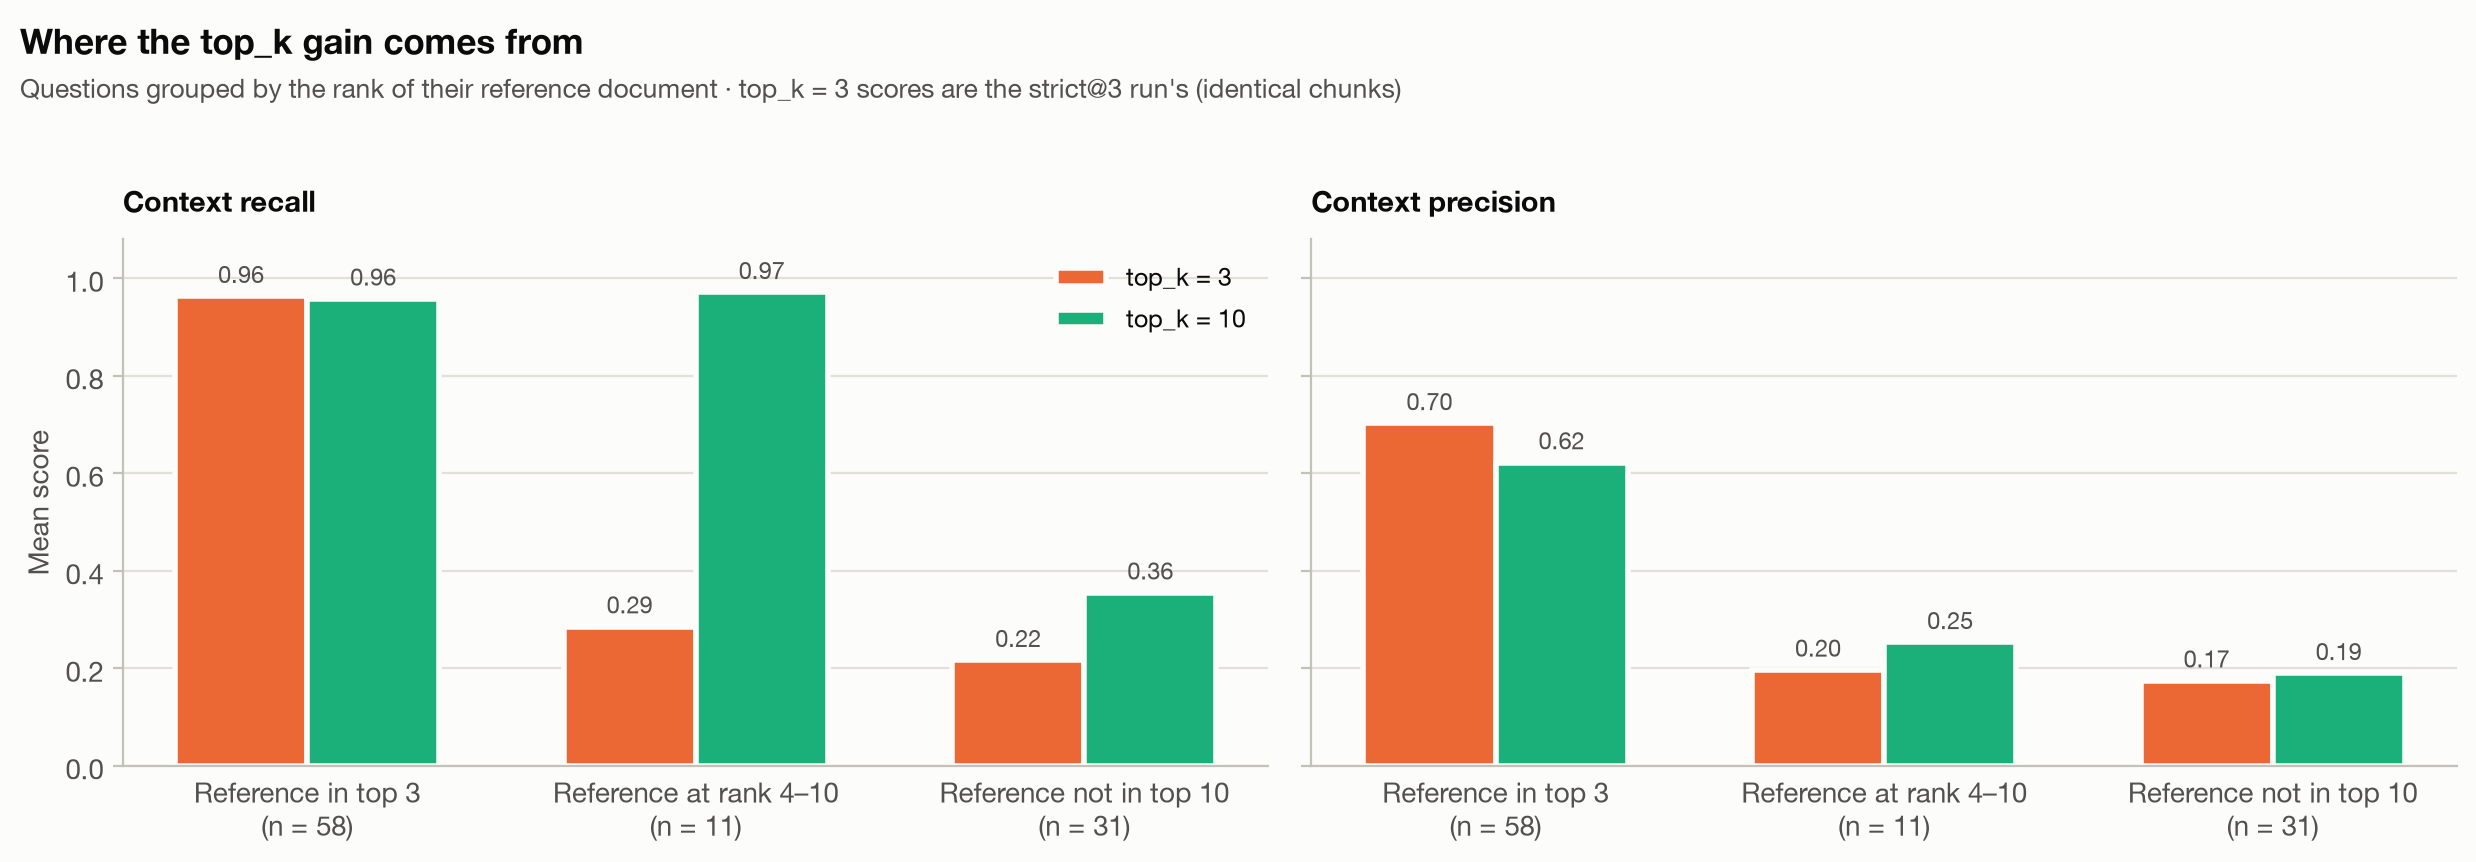

Context recall          Context precision         
                               top_k 3 top_k 10           top_k 3 top_k 10
gold_group                                                                
Reference in top 3               0.963    0.958             0.703    0.622
Reference at rank 4–10           0.286    0.971             0.197    0.253
Reference not in top 10          0.217    0.355             0.175    0.190

In [15]:
gorder = ["Reference in top 3", "Reference at rank 4–10", "Reference not in top 10"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
w = 0.34
for ax, m in zip(axes, ["context_recall", "context_precision"]):
    for k, cfg in enumerate(["relaxed@3", "relaxed@10"]):
        vals = [per_q.loc[q.gold_group == g, (cfg, m)].mean() for g in gorder]
        bars = ax.bar(np.arange(3) + (k - 0.5) * w, vals, width=w, color=RUN_COLORS[cfg], edgecolor=SURFACE, lw=2,
                      label=f"top_k = {cfg.split('@')[1]}")
        label_bars(ax, bars)
    ax.set_xticks(range(3), [f"{g}\n(n = {(q.gold_group == g).sum()})" for g in gorder])
    ax.set_title(SHORT[m])
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylim(0, 1.08)
axes[0].set_ylabel("Mean score")
axes[0].legend(loc="upper right")
fig.tight_layout(rect=(0, 0, 1, header(fig, "Where the top_k gain comes from",
                                       "Questions grouped by the rank of their reference document · top_k = 3 scores are the strict@3 run's (identical chunks)")))
plt.show()

pd.DataFrame({
    (SHORT[m], f"top_k {cfg.split('@')[1]}"): per_q[(cfg, m)].groupby(q.gold_group, observed=True).mean()
    for m in ["context_recall", "context_precision"] for cfg in ["relaxed@3", "relaxed@10"]
}).round(3)

**Context recall** jumps for exactly the 11 questions whose reference sits at ranks 4–10 (≈0.29 → 0.97). It barely changes when the reference was already in the top 3, and only partly recovers when the reference is never retrieved (0.22 → 0.36, from fragments in other documents).

**Context precision falls even where retrieval did not get worse.** For the 58 questions whose reference is already in the top 3, precision drops from 0.70 to 0.62. RAGAS context precision is a rank-weighted average over the chunks the judge marks useful, so every extra useful chunk found low in the list pulls the average down. A worked example:

| Chunk usefulness by rank | Score |
|---|---|
| `[1, 0, 0]` (top_k = 3) | (1/1) ÷ 1 = **1.00** |
| `[1, 0, 0, 0, 0, 1, 0, 0, 0, 0]` (top_k = 10) | (1/1 + 2/6) ÷ 2 = **0.67** |

The second list contains *more* useful evidence but scores lower. With large `top_k`, read context precision as "how well-ordered is the list", not "is the useful content there". A reranker is the usual fix.

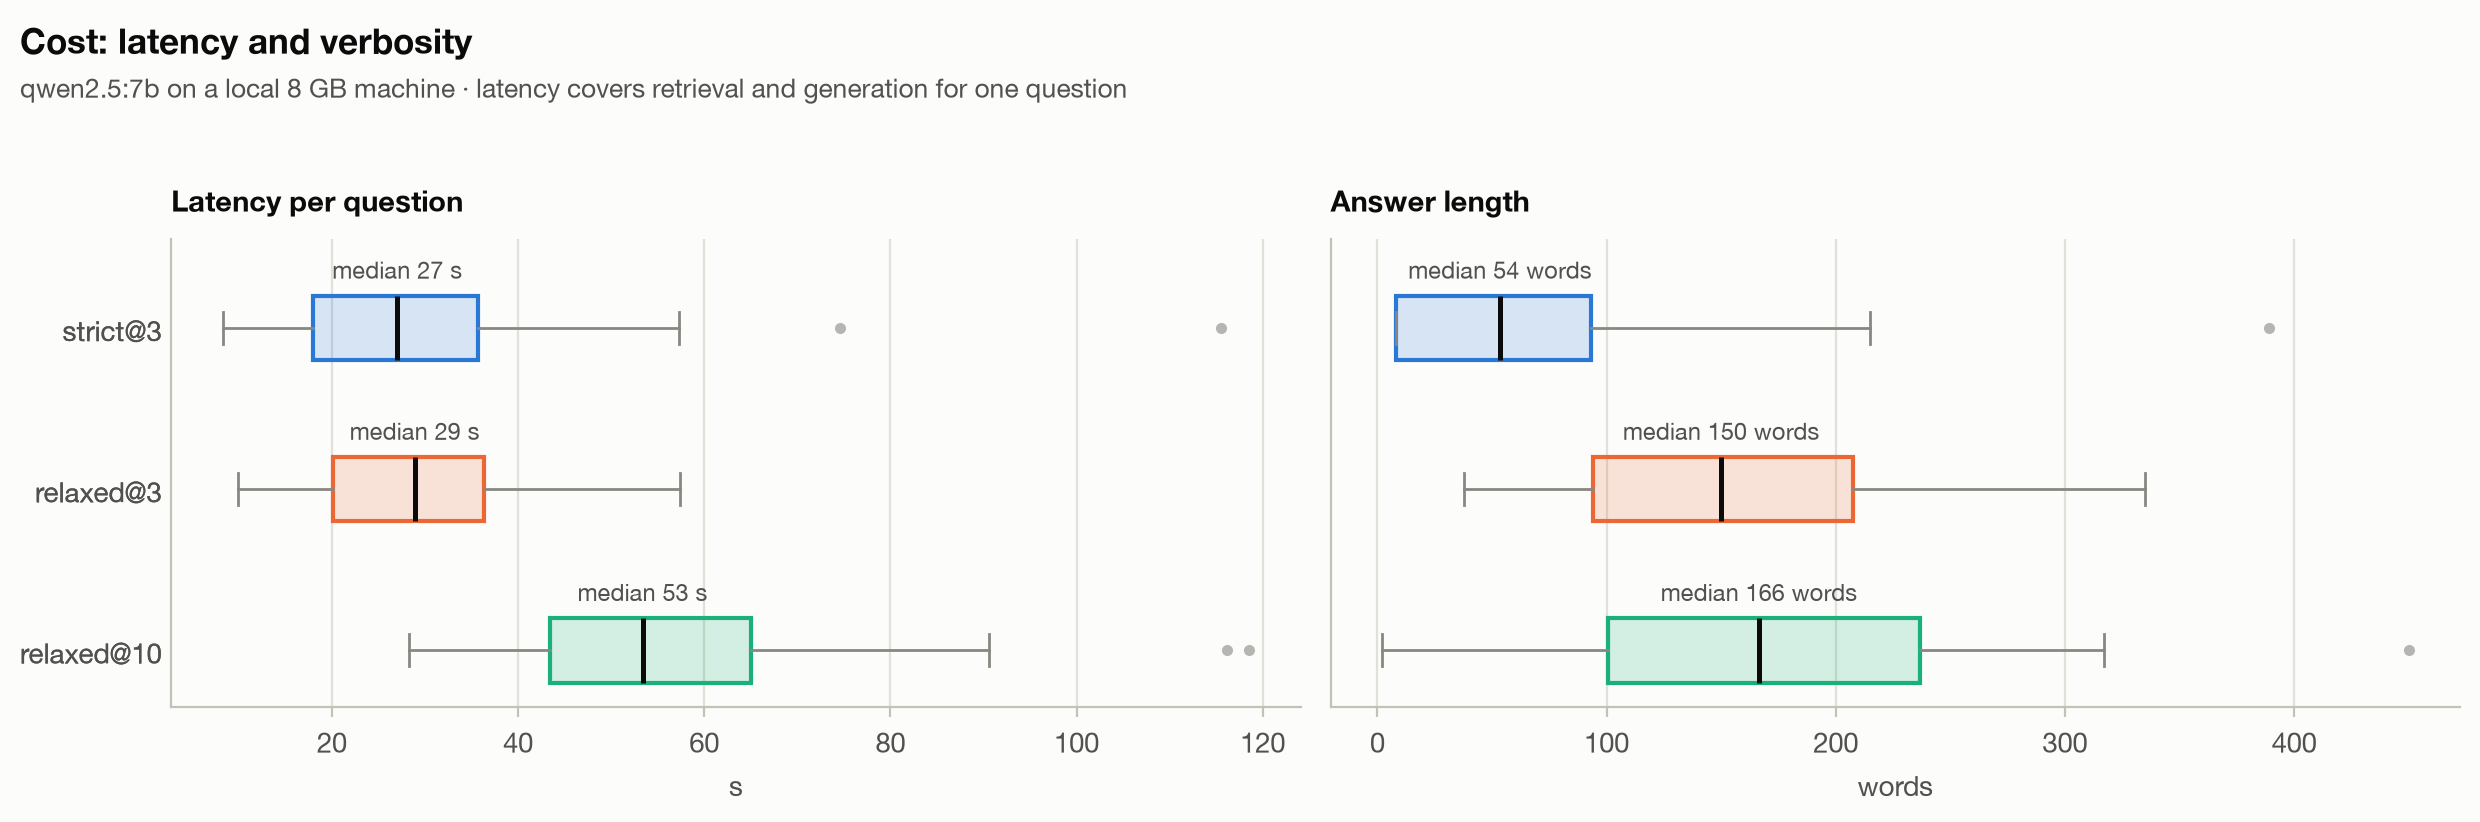

,strict@3,relaxed@3,relaxed@10
mean latency (s),29.5,29.1,55.3
median latency (s),27.0,28.9,53.4
p90 latency (s),50.5,43.7,74.8
mean answer words,61.8,153.9,170.2


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, (col, unit, title) in zip(axes, [("latency", "s", "Latency per question"),
                                         ("words", "words", "Answer length")]):
    data = [q[f"{col} {cfg}"].to_numpy() for cfg in PATH]
    bp = ax.boxplot(data, orientation="horizontal", tick_labels=PATH, patch_artist=True, widths=0.4,
                    medianprops=dict(color=INK, lw=1.8), whiskerprops=dict(color=MUTED, lw=1),
                    capprops=dict(color=MUTED, lw=1),
                    flierprops=dict(marker="o", ms=4, mfc=MUTED, mec="none", alpha=0.6))
    for patch, cfg in zip(bp["boxes"], PATH):
        patch.set(facecolor=to_rgba(RUN_COLORS[cfg], 0.18), edgecolor=RUN_COLORS[cfg], lw=1.5)
    for i, d in enumerate(data, 1):
        ax.text(np.median(d), i - 0.36, f"median {np.median(d):.0f} {unit}", ha="center", va="center",
                fontsize=8.5, color=INK_2)
    ax.set_title(title)
    ax.set_xlabel(unit)
    ax.set_ylim(0.45, 3.35)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].invert_yaxis()
fig.tight_layout(rect=(0, 0, 1, header(fig, "Cost: latency and verbosity",
                                       "qwen2.5:7b on a local 8 GB machine · latency covers retrieval and generation for one question")))
plt.show()

pd.DataFrame({cfg: {"mean latency (s)": q[f"latency {cfg}"].mean(), "median latency (s)": q[f"latency {cfg}"].median(),
                    "p90 latency (s)": q[f"latency {cfg}"].quantile(0.9), "mean answer words": q[f"words {cfg}"].mean()}
              for cfg in PATH}).round(1)

**`TOP_K` takeaways**

* Retrieving 10 chunks instead of 3 roughly **doubles generation latency** (median 29 s → 53 s), because the model has to read a much longer prompt. Changing the prompt alone barely changed latency.
* The answer-relevancy gain (+0.09) has a direct cause: with more context the relaxed prompt hedges less (21 → 11 hedged answers). On the 33 questions the strict prompt refused, answer relevancy rose from 0.09 to 0.36.
* Faithfulness rose slightly (+0.04, CI includes 0), so more context did not lead to more unsupported claims.

## 10. Runtime cost

These figures come from the run logs in `eval/logs/`, not from the result files. All runs use one local Ollama model, with one judge call at a time.

| Run | Answer generation | Judge calls | Judge wall time | Seconds per judge call | Failed judge calls |
|---|---|---|---|---|---|
| A: strict@3 (stock judge) | 100 × 29.5 s mean | 400 (4 metrics) | 9 h 14 m | 83 | 0 |
| B: re-score answer relevancy | cached from A | 100 | 30 m | 18 | 0 |
| C: relaxed@3 | 100 × 29.1 s mean | 200 (2 metrics) | 3 h 36 m | 65 | 0 |
| D: relaxed@10 | 100 × 55.3 s mean | 400 (4 metrics) | 10 h 50 m | 98 | 1 (context recall on `fiqa_0007`, timeout) |

Judging costs far more than generating: a full 4-metric run takes about 10 hours of judge time, against roughly 50–90 minutes of generation. Calls with 10 chunks are the slowest, because context precision makes one judge call per chunk and context recall has to read all the chunks.

## 11. Question-level view

Each column is one question and each row is one metric under one configuration. Questions are sorted by the rank of their reference document. The block structure shows that retrieval drives most metrics. Inherited rows are left out, and the one failed judge call is shown in gray.

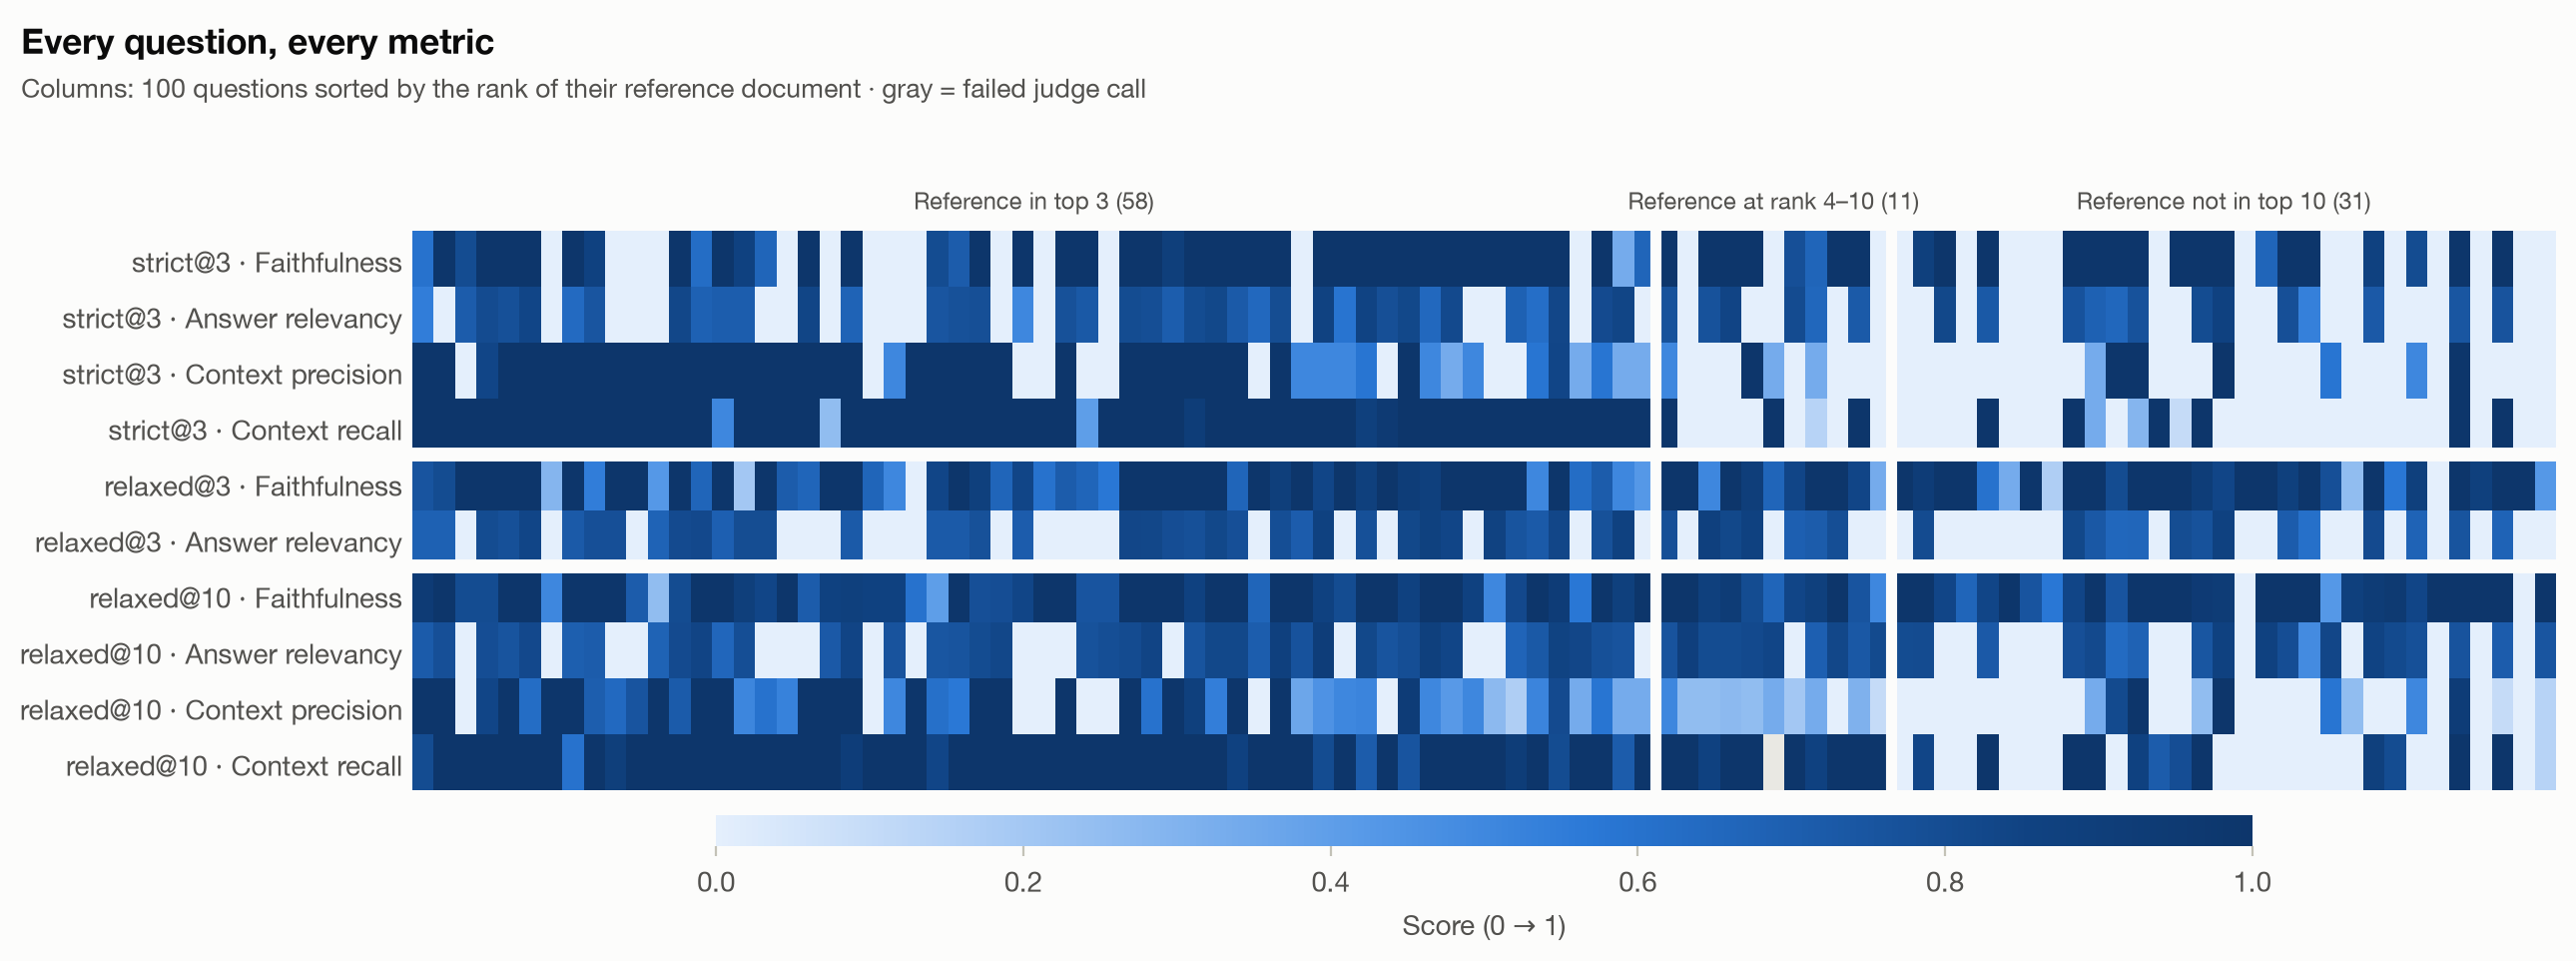

In [17]:
order = q.assign(_r=q.gold_rank.fillna(99)).sort_values("_r", kind="stable").index
rows = [(cfg, m) for cfg in PATH for m in METRICS if (cfg, m) in per_q and (cfg, m) not in INHERITED]
H = np.array([per_q[r].reindex(order).to_numpy(float) for r in rows])

fig, ax = plt.subplots(figsize=(13, 4.9))
im = ax.imshow(np.ma.masked_invalid(H), cmap=SEQ, vmin=0, vmax=1, aspect="auto", interpolation="nearest")
ax.set_yticks(range(len(rows)), [f"{cfg} · {SHORT[m]}" for cfg, m in rows])
ax.set_xticks([])
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(1, len(rows)):                                    # gaps between configurations
    if rows[i][0] != rows[i - 1][0]:
        ax.axhline(i - 0.5, color=SURFACE, lw=5)
sorted_groups = q.gold_group.reindex(order).to_numpy()
start = 0
for g in gorder:
    n = int((sorted_groups == g).sum())
    if start:
        ax.axvline(start - 0.5, color=SURFACE, lw=4)
    ax.text(start + n / 2 - 0.5, -0.8, f"{g} ({n})", ha="center", va="bottom", fontsize=8.5, color=INK_2)
    start += n
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.04, aspect=50)
cb.set_label("Score (0 → 1)", color=INK_2)
cb.outline.set_visible(False)
fig.tight_layout(rect=(0, 0, 1, header(fig, "Every question, every metric",
                                       "Columns: 100 questions sorted by the rank of their reference document · gray = failed judge call")))
plt.show()

## 12. Caveats

1. **The judge grades its own model.** `qwen2.5:7b` both generates and judges, so self-preference bias is possible. A 7B judge is also noisier than the GPT-4-class judges RAGAS is usually run with. Treat the absolute values as internal and compare configurations with each other, not with published numbers.
2. **The confidence intervals cover question sampling only, not judge noise.** Each configuration was judged once at temperature 0. Re-judging the same answers would reveal how much scores move run to run, and that noise is not in these intervals.
3. **n = 100.** Differences in a mean below about 0.05 are not resolvable here, and several effects sit close to that line (faithfulness under `TOP_K`, context precision).
4. **Answer-relevancy scores from the stock and calibrated judge prompts are not comparable** (§7).
5. **The relaxed@3 context metrics were inherited, not re-scored.** This is justified (identical chunks, and the metrics ignore the answer), but those cells come from the strict@3 judge run.
6. **strict@10 is missing**, so the `TOP_K` effect is measured under the relaxed prompt only.
7. **Injecting the references makes retrieval easier than a real deployment**, where the answer may not exist in the corpus at all. The other 99 references are also unusually strong distractors, since they are in the same answer style. The `gold_rank` matching uses document names, plus text matching for references that were already in the corpus.
8. **Scores are coarse.** For strict@3, 79–90% of faithfulness, context precision and context recall scores are exactly 0 or 1. For the relaxed configurations, about half of faithfulness and context precision scores are (table below). A mean therefore partly measures the share of questions that pass or fail outright, rather than a fine-grained quality level.
9. **One failed judge call** (relaxed@10 context recall on `fiqa_0007`) means that mean is over 99 questions.
10. **Documentation drift.** The README lists `TOP_K = 5` as the default, but `config.py` uses 3. All runs here used 3 or 10.

In [18]:
coarse = pd.DataFrame({
    f"{cfg} · {SHORT[m]}": {"exactly 0": (s == 0).mean(), "between 0 and 1": ((s > 0) & (s < 1)).mean(),
                            "exactly 1": (s == 1).mean()}
    for (cfg, m), s in per_q.items() if (cfg, m) not in INHERITED for s in [s.dropna()]
}).T
(coarse * 100).round(0).astype(int).rename(columns=lambda c: c + " (%)")

,exactly 0 (%),between 0 and 1 (%),exactly 1 (%)
strict@3 · stock AR judge · Answer relevancy,66,34,0
strict@3 · Faithfulness,31,17,52
strict@3 · Answer relevancy,42,58,0
strict@3 · Context precision,41,21,38
strict@3 · Context recall,29,10,61
relaxed@3 · Faithfulness,2,50,48
relaxed@3 · Answer relevancy,41,59,0
relaxed@10 · Faithfulness,2,54,44
relaxed@10 · Answer relevancy,30,70,0
relaxed@10 · Context precision,29,50,21


## 13. Conclusions and next experiments

**What each constant does**

| Constant | Recommended value | Why |
|---|---|---|
| AR judge prompt | **calibrated** | The stock prompt scored 33 real answers as 0 because the 7B judge misread caveats as evasion. |
| Generation prompt | **relaxed, with the hedging fixed** | It removes the 33 refusals, 16 of which had the answer in their chunks. It costs about 0.05 faithfulness on answerable questions and makes answers 2.5× longer. |
| `TOP_K` | **5 to 10** | 10 gives the best recall and relevancy, at about 2× latency and slightly lower precision. The hit-rate curve suggests 5 captures most of the gain. |

**Next experiments, in priority order**

1. **Fix the relaxed prompt's hedging.** Tell the model not to include the refusal sentence, or say "the context does not provide…", when it goes on to give a partial answer. 21 answers at `top_k = 3` (11 at `top_k = 10`) score 0 on answer relevancy for this reason alone. This is a cheap re-run (`--prompt` variant, faithfulness + answer relevancy only).
2. **Run strict@10** (`python eval/run_eval.py --top-k 10`) to complete the 2×2 grid and measure the prompt × `TOP_K` interaction.
3. **Try `top_k = 5`.** It needs one generation run plus the judge, and the hit-rate curve predicts most of the recall gain at lower latency.
4. **Add a reranker** (for example a cross-encoder over the top 10–20) to recover context precision at a large `top_k`.
5. **Raise the retrieval ceiling.** 31 questions never retrieve their reference. Try hybrid BM25 + vector search, a different embedding model, query rewriting, or a different chunk size.
6. **Make the judge more trustworthy.** Use a different, ideally larger, judge model than the generator, and judge one configuration twice to measure judge noise before trusting deltas under about 0.05.

### Reproducing the runs

```bash
python eval/run_eval.py                                                     # A: strict, top_k=3, all metrics (stock AR prompt at the time)
python eval/run_eval.py --metrics answer_relevancy                          # B: re-score the cached answers, calibrated AR prompt
python eval/run_eval.py --prompt relaxed --metrics faithfulness answer_relevancy   # C: relaxed, top_k=3
python eval/run_eval.py --top-k 10 --prompt relaxed                         # D: relaxed, top_k=10
```

`run_eval.py` writes `results*.json` and `pipeline_cache*.json` into `eval/`. The files used here were afterwards moved to `eval/results/` and `eval/cache/` (run A's `results.json` was renamed `results_normal.json`). The stock answer-relevancy prompt in run A predates commit `d75a86e`, which added `CalibratedResponseRelevancePrompt`.